# Combined Long LIWC Linguistic Features 

This notebook reproduces the original feature logic and adapts grouping to `original` vs `rewrite` using `text_type`, with added spaCy POS features (adjectives, nouns, verbs, adverbs).

In [1]:
from pathlib import Path
from collections import Counter

import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
import textstat
import pingouin as pg

from scipy.stats import permutation_test
from statsmodels.stats.multitest import multipletests

In [2]:
# Ensure the required spaCy transformer model is available in the environment.
if not spacy.util.is_package("en_core_web_trf"):
    raise RuntimeError(
        "Missing spaCy model 'en_core_web_trf'. Install it once in your environment with: "
        "python -m spacy download en_core_web_trf"
    )

print("spaCy model 'en_core_web_trf' is available.")

spaCy model 'en_core_web_trf' is available.


In [3]:
ROOT = Path('..').resolve()
DATA_PATH = ROOT / 'data' / 'combined_long_liwc.csv'
CONCR_PATH = ROOT / 'linguisticFeatures' / 'Brysbaert concreteness scoring.xlsx'
OUTPUT_PATH = ROOT / 'output' / 'combined_long_liwc_lingfeat.csv'
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, encoding='utf-8')
required_cols = {'text', 'text_type', 'WC'}
missing = sorted(required_cols - set(df.columns))
if missing:
    raise ValueError(f'Missing required columns: {missing}')

# Keep variable naming aligned with the original notebook flow.
df_h = df[df['text_type'].astype(str).str.lower() == 'original']
df_d = df[df['text_type'].astype(str).str.lower() == 'rewrite']

print(f'Rows: {len(df):,}')
print(f'Original rows: {len(df_h):,}')
print(f'Rewrite rows: {len(df_d):,}')

Rows: 1,002
Original rows: 501
Rewrite rows: 501


In [4]:
def load_spacy_model():
    try:
        return spacy.load('en_core_web_trf')
    except OSError as exc:
        raise RuntimeError(
            "Missing spaCy model 'en_core_web_trf'. Install it with: "
            "python -m spacy download en_core_web_trf"
        ) from exc

nlp = load_spacy_model()
docs = [doc for doc in nlp.pipe(df['text'].fillna(''), batch_size=128)]

/Users/luccapfruender/miniconda3/envs/rq2-nlp/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [16]:
def tokenize(doc):
    tokens = [token.text for token in doc if not (token.is_punct or token.is_space)]
    return ' '.join(tokens).lower()

def preprocessed_text(doc):
    clean_tokens = [
        token.lemma_
        for token in doc
        if not (token.is_punct or token.is_space or token.is_stop)
    ]
    return ' '.join(clean_tokens).lower()

tokens = [tokenize(doc) for doc in docs]
clean_text = [preprocessed_text(doc) for doc in docs]

df['tokens'] = tokens
df['clean_text'] = clean_text

word_counts = [len(text.split()) for text in df['tokens']]
df['word_counts'] = word_counts

# Recreate group splits now that word_counts is added to df
df_h = df[df['text_type'].astype(str).str.lower() == 'original']
df_d = df[df['text_type'].astype(str).str.lower() == 'rewrite']

df[['text_type', 'word_counts', 'tokens', 'clean_text']].head()

,text_type,word_counts,tokens,clean_text
0,original,142,i recently went on vacation with my family we ...,recently go vacation family go point magu mali...
1,rewrite,127,i recently went on vacation with a few other f...,recently go vacation family members.we go mali...
2,original,128,about three months ago i started going to see ...,month ago start go therapist suffer anxiety de...
3,rewrite,131,around three months ago i started seeing a the...,month ago start see therapist mental health re...
4,original,125,i have a niece who i adore and this is a day i...,niece adore day life pick 9 start day have fun...


## Word Count Exploration

Quick checks on text length distribution before feature extraction.

,count,min,max,mean,std,median
text_type,,,,,,
original,501,104,155,130.29,9.37,129.0
rewrite,501,88,178,129.56,18.33,128.0


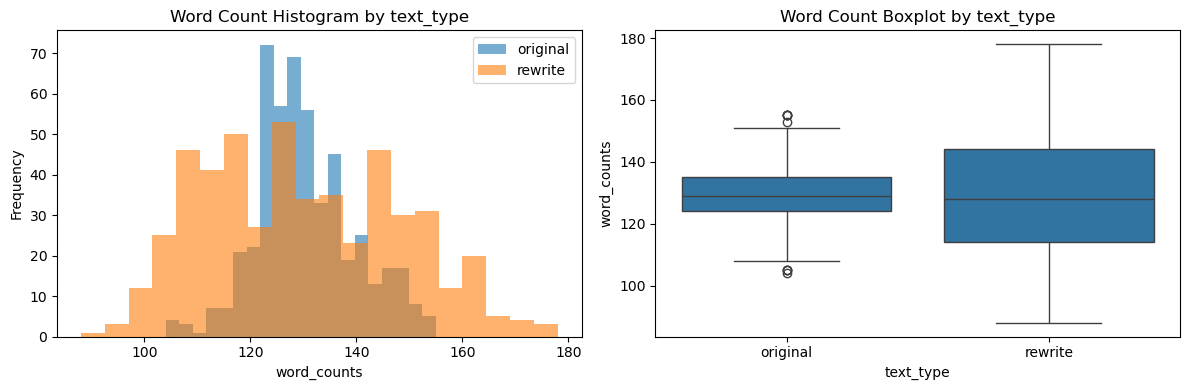

In [6]:
word_count_summary = (
    df.groupby("text_type", dropna=False)["word_counts"]
    .agg(["count", "min", "max", "mean", "std", "median"])
    .round(2)
)
display(word_count_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for label, group in df.groupby("text_type"):
    axes[0].hist(group["word_counts"], bins=20, alpha=0.6, label=str(label))
axes[0].set_title("Word Count Histogram by text_type")
axes[0].set_xlabel("word_counts")
axes[0].set_ylabel("Frequency")
axes[0].legend()

sns.boxplot(data=df, x="text_type", y="word_counts", ax=axes[1])
axes[1].set_title("Word Count Boxplot by text_type")

plt.tight_layout()
plt.show()

## Textstat Features

Compute sentence- and readability-based text statistics.

In [7]:
text_stats_rows = []
for text in df['text'].fillna(''):
    num_sentences = textstat.sentence_count(text)
    num_words = textstat.lexicon_count(text)
    num_syllables = textstat.syllable_count(text)
    avg_syllables_per_word = (num_syllables / num_words) if num_words else 0
    fk_grade = textstat.flesch_kincaid_grade(text)
    fk_read = textstat.flesch_reading_ease(text)
    text_stats_rows.append({
        'num_sentences': num_sentences,
        'num_syllables': num_syllables,
        'avg_syllables_per_word': avg_syllables_per_word,
        'fk_grade': fk_grade,
        'fk_read': fk_read
    })

text_stats_df = pd.DataFrame(text_stats_rows)
text_stats_df.head()

,num_sentences,num_syllables,avg_syllables_per_word,fk_grade,fk_read
0,12,177,1.246479,3.733451,89.372054
1,6,167,1.314961,8.181535,74.105164
2,8,172,1.365079,6.660437,75.363036
3,8,184,1.415385,7.449038,70.599712
4,10,167,1.357724,5.228138,79.487085


## LIWC Composite Features

Build the LIWC-based composite variables used in the feature table.

In [8]:
liwc_final = df[[
    'Analytic', 'Authentic', 'Tone', 'tone_pos', 'tone_neg',
    'focuspast', 'focuspresent', 'focusfuture', 'Cognition', 'memory'
]].copy()

liwc_final.loc[:, 'Self-reference'] = df['i'] + df['we']
liwc_final.loc[:, 'Other-reference'] = df['shehe'] + df['they'] + df['you']
liwc_final.loc[:, 'Contextual Embedding'] = df['space'] + df['motion'] + df['time']
liwc_final.loc[:, 'Perceptual Details'] = df['attention'] + df['visual'] + df['auditory'] + df['feeling']
liwc_final.loc[:, 'Reality Monitoring'] = (
    liwc_final['Perceptual Details'] + liwc_final['Contextual Embedding'] + df['Affect'] - df['Cognition']
)

liwc_final.head()

,Analytic,Authentic,Tone,tone_pos,tone_neg,focuspast,focuspresent,focusfuture,Cognition,memory,Self-reference,Other-reference,Contextual Embedding,Perceptual Details,Reality Monitoring
0,83.86,99.00,75.09,3.52,0.00,9.86,0.00,1.41,8.45,0.00,15.50,0.00,29.58,1.41,26.06
1,91.51,96.50,56.84,2.34,0.00,10.16,0.00,1.56,14.84,0.00,11.72,0.00,24.22,1.56,13.28
2,23.27,99.00,1.00,0.00,3.97,18.25,0.79,1.59,34.13,1.59,8.73,1.59,19.04,4.76,-6.36
3,10.54,94.47,6.78,1.54,3.08,15.38,0.00,0.00,30.77,0.00,10.77,2.31,13.85,2.31,-9.99
4,62.96,65.56,99.00,8.13,0.00,7.32,0.81,0.81,14.63,0.00,12.19,0.81,17.08,0.81,11.39


In [9]:
liwc_final.describe()

,Analytic,Authentic,Tone,tone_pos,tone_neg,focuspast,focuspresent,focusfuture,Cognition,memory,Self-reference,Other-reference,Contextual Embedding,Perceptual Details,Reality Monitoring
count,1002.000000,1002.000000,992.000000,1002.000000,1002.000000,1002.000000,1002.000000,1002.000000,1002.000000,1002.000000,1002.000000,1002.000000,1002.000000,1002.000000,1002.000000
mean,44.831078,76.058792,55.707571,4.125080,1.555250,9.568214,2.308782,1.118553,24.953892,0.329331,9.799411,3.177525,14.584222,2.244102,-2.164701
std,28.318313,26.506875,34.207492,2.833804,1.726104,3.342272,2.380819,1.377643,5.548821,0.587815,3.015467,3.146121,4.520929,1.759647,7.545233
min,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.450000,0.000000,0.000000,0.000000,2.140000,0.000000,-28.210000
25%,19.300000,60.995000,20.230000,1.970000,0.000000,7.260000,0.680000,0.000000,20.840000,0.000000,7.840000,0.770000,11.372500,0.880000,-7.087500
50%,43.780000,88.030000,59.080000,3.645000,0.875000,9.490000,1.630000,0.790000,25.000000,0.000000,9.700000,2.210000,14.170000,1.870000,-2.370000
75%,69.452500,97.330000,88.070000,5.650000,2.435000,11.930000,3.420000,1.630000,28.570000,0.710000,12.000000,4.860000,17.165000,3.135000,2.987500
max,99.000000,99.000000,99.000000,15.750000,9.150000,21.310000,11.940000,10.940000,42.110000,4.000000,17.360000,14.730000,30.950000,12.620000,26.060000


## Named Entity Recognition (NER) Features

Extract NER counts and grouped NER constructs.

In [10]:
# NER extraction and grouped NER constructs
ner = []
for doc in docs:
    entities = set((entity.text, entity.label_) for entity in doc.ents)
    entity_counts = {}
    for entity, label in entities:
        if label not in entity_counts:
            entity_counts[label] = {entity: 1}
        elif entity not in entity_counts[label]:
            entity_counts[label][entity] = 1
        else:
            entity_counts[label][entity] += 1
    ner.append(entity_counts)

ner_df = pd.DataFrame.from_records([
    {col: sum(inner.values()) for col, inner in d.items()} for d in ner
]).fillna(0)
ner_df = ner_df.div(df['word_counts'].replace(0, 1), axis=0) * 100
ner_df['text_type'] = df['text_type'].values

def safe_col(frame, col):
    if col in frame.columns:
        return frame[col]
    return pd.Series(0.0, index=frame.index)

new_ner = pd.DataFrame(index=ner_df.index)
new_ner['Temporal details'] = safe_col(ner_df, 'DATE') + safe_col(ner_df, 'TIME') + safe_col(ner_df, 'EVENT')
new_ner['Spatial details'] = safe_col(ner_df, 'GPE') + safe_col(ner_df, 'LOC') + safe_col(ner_df, 'FAC')
new_ner['People'] = safe_col(ner_df, 'PERSON')
new_ner['Quantity details'] = (
    safe_col(ner_df, 'PERCENT') + safe_col(ner_df, 'MONEY') + safe_col(ner_df, 'QUANTITY')
    + safe_col(ner_df, 'CARDINAL') + safe_col(ner_df, 'ORDINAL')
)

new_ner.head()

,Temporal details,Spatial details,People,Quantity details
0,1.408451,1.408451,0.0,0.704225
1,0.787402,1.574803,0.0,0.787402
2,1.562500,0.000000,0.0,1.562500
3,2.290076,0.000000,0.0,1.526718
4,4.000000,0.000000,0.0,0.000000


In [11]:
# NER diagnostics
print("Missing values per NER feature:")
display(new_ner.isna().sum())

print("NER feature summary statistics:")
display(new_ner.describe())

Missing values per NER feature:


Temporal details    0
Spatial details     0
People              0
Quantity details    0
dtype: int64

NER feature summary statistics:


,Temporal details,Spatial details,People,Quantity details
count,1002.000000,1002.000000,1002.000000,1002.000000
mean,1.678255,0.357330,0.221930,0.468782
std,1.194769,0.835531,0.615930,0.652258
min,0.000000,0.000000,0.000000,0.000000
25%,0.793651,0.000000,0.000000,0.000000
50%,1.515152,0.000000,0.000000,0.000000
75%,2.380952,0.000000,0.000000,0.787402
max,6.015038,7.500000,8.403361,5.769231


## Concreteness 

Compute average concreteness scores.

In [12]:
# Concreteness
concr_df = pd.read_excel(CONCR_PATH)

def get_avg_concr_score(text):
    tokens = set(str(text).split())
    matches = concr_df['Word'].str.lower().isin(tokens)
    scores = concr_df.loc[matches, 'Conc.M'].values
    return float(scores.mean()) if len(scores) > 0 else 0.0

df['concr_score'] = df['clean_text'].apply(get_avg_concr_score)

df[['concr_score']].head()

/var/folders/qy/qlzcmrrs6c3gkvkt664k0m6c0000gn/T/ipykernel_3580/1061669299.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['concr_score'] = df['clean_text'].apply(get_avg_concr_score)


,concr_score
0,3.986000
1,3.935676
2,3.020645
3,2.782143
4,3.367059


## POS Features

Compute POS-tag percentages (adjectives, nouns, verbs, adverbs) from the parsed spaCy docs.

In [13]:
# POS-tag percentages requested: adjectives, nouns, verbs, adverbs.
pos_rows = []
for doc, wc in zip(docs, df['word_counts'].replace(0, 1)):
    tags = Counter(token.pos_ for token in doc if not (token.is_punct or token.is_space))
    pos_rows.append({
        'adj_pct': tags.get('ADJ', 0) / wc * 100,
        'noun_pct': tags.get('NOUN', 0) / wc * 100,
        'verb_pct': tags.get('VERB', 0) / wc * 100,
        'adverb_pct': tags.get('ADV', 0) / wc * 100
    })
pos_tags_df = pd.DataFrame(pos_rows)

pos_tags_df.head()

,adj_pct,noun_pct,verb_pct,adverb_pct
0,3.521127,21.830986,16.901408,5.633803
1,5.511811,20.472441,14.960630,4.724409
2,6.250000,15.625000,14.843750,4.687500
3,4.580153,15.267176,13.740458,9.923664
4,9.600000,20.000000,14.400000,3.200000


## Feature Merge and Export

Merge all feature blocks into a final table and save compact plus linked outputs.

In [14]:
# Final scoring dataframe (same merge logic, adapted label and with POS tags included)
labels = pd.Series(df['text_type']).reset_index(drop=True)
word_counts_series = pd.Series(df['word_counts']).reset_index(drop=True)
concr_score = df['concr_score'].reset_index(drop=True)

scoring_df = pd.concat([
    labels.rename('text_type'),
    word_counts_series.rename('word_counts'),
    text_stats_df.reset_index(drop=True),
    liwc_final.reset_index(drop=True),
    concr_score,
    new_ner.reset_index(drop=True),
    pos_tags_df.reset_index(drop=True)
], axis=1)

# Keep a compact feature table.
scoring_df.to_csv(OUTPUT_PATH, index=False)
print(f'Saved: {OUTPUT_PATH}')
print(f'Shape: {scoring_df.shape}')

# Also save a linked table that keeps identifiers/text from the original CSV.
link_cols = [
    col for col in [
        'rewrite_id', 'statement_id', 'topic_label', 'attack_modality',
        'original_veracity', 'target_veracity', 'original_label', 'rewrite_label',
        'asr', 'text_type', 'text'
    ] if col in df.columns
]

scoring_with_keys = pd.concat([
    df[link_cols].reset_index(drop=True),
    scoring_df.drop(columns=['text_type'], errors='ignore').reset_index(drop=True)
], axis=1)

linked_output_path = OUTPUT_PATH.with_name('combined_long_liwc_lingfeat_linked.csv')
scoring_with_keys.to_csv(linked_output_path, index=False)
print(f'Saved: {linked_output_path}')
print(f'Linked shape: {scoring_with_keys.shape}')

scoring_with_keys.head()

Saved: /Users/luccapfruender/Desktop/analysesStudy1Python/output/combined_long_liwc_lingfeat.csv
Shape: (1002, 31)
Saved: /Users/luccapfruender/Desktop/analysesStudy1Python/output/combined_long_liwc_lingfeat_linked.csv
Linked shape: (1002, 41)


,rewrite_id,statement_id,topic_label,attack_modality,original_veracity,target_veracity,original_label,rewrite_label,asr,text_type,...,Reality Monitoring,concr_score,Temporal details,Spatial details,People,Quantity details,adj_pct,noun_pct,verb_pct,adverb_pct
0,1,889,Vacation/Trip,human,Truthful,Deceptive,1,1,0,original,...,26.06,3.986000,1.408451,1.408451,0.0,0.704225,3.521127,21.830986,16.901408,5.633803
1,1,889,Vacation/Trip,human,Truthful,Deceptive,1,1,0,rewrite,...,13.28,3.935676,0.787402,1.574803,0.0,0.787402,5.511811,20.472441,14.960630,4.724409
2,2,2177,Hospital/Injury,human,Truthful,Deceptive,1,1,0,original,...,-6.36,3.020645,1.562500,0.000000,0.0,1.562500,6.250000,15.625000,14.843750,4.687500
3,2,2177,Hospital/Injury,human,Truthful,Deceptive,1,1,0,rewrite,...,-9.99,2.782143,2.290076,0.000000,0.0,1.526718,4.580153,15.267176,13.740458,9.923664
4,3,2535,Family,human,Deceptive,Truthful,0,1,1,original,...,11.39,3.367059,4.000000,0.000000,0.0,0.000000,9.600000,20.000000,14.400000,3.200000


## Extended Step-by-Step Checks

This section mirrors the longer legacy workflow so you can inspect each intermediate diagnostic before downstream analysis.

In [17]:
def num_of_words_stat(word_counts_vec):
    min_words = word_counts_vec.min()
    max_words = word_counts_vec.max()
    mean_words = word_counts_vec.mean()
    std_words = word_counts_vec.std()

    print(f"Minimum number of words: {min_words}")
    print(f"Maximum number of words: {max_words}")
    print(f"Average number of words: {mean_words:.2f}")
    print(f"Standard deviation number of words: {std_words:.2f}")

    return min_words, max_words, mean_words, std_words

print("All texts:")
_ = num_of_words_stat(df["word_counts"])

print("\nOriginal texts:")
_ = num_of_words_stat(df_h["word_counts"])

print("\nRewrite texts:")
_ = num_of_words_stat(df_d["word_counts"])

All texts:
Minimum number of words: 88
Maximum number of words: 178
Average number of words: 129.93
Standard deviation number of words: 14.55

Original texts:
Minimum number of words: 104
Maximum number of words: 155
Average number of words: 130.29
Standard deviation number of words: 9.37

Rewrite texts:
Minimum number of words: 88
Maximum number of words: 178
Average number of words: 129.56
Standard deviation number of words: 18.33


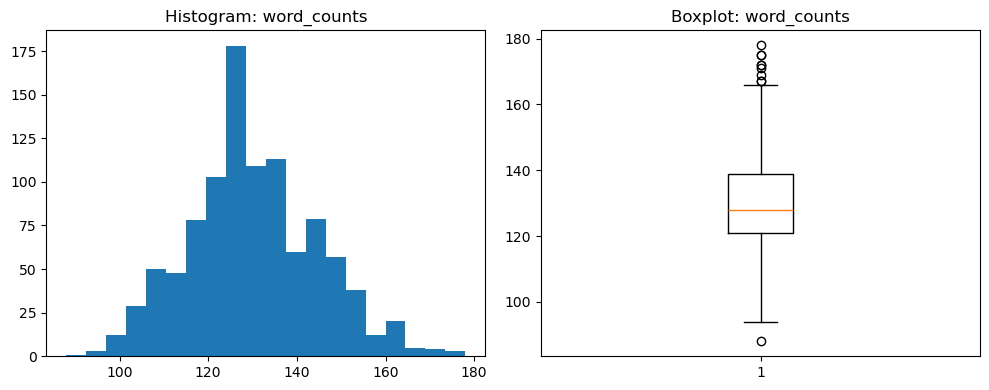

,rewrite_id,statement_id,topic_label,attack_modality,original_veracity,target_veracity,original_label,rewrite_label,asr,text_type,...,Comma,QMark,Exclam,Apostro,OtherP,Emoji,tokens,clean_text,word_counts,concr_score
925,570,4174,Home/Moving,llm,Deceptive,Truthful,0,1,1,rewrite,...,7.02,0.0,0.0,2.92,1.75,0,i 've been reflecting on the events of last ni...,reflect event night solidify need change livin...,178,2.812500
615,415,1135,Funeral/Death,llm,Truthful,Deceptive,1,1,0,rewrite,...,9.09,0.0,0.0,1.82,4.24,0,as i look back on my family 's story i am remi...,look family story remind son marry 17 child 11...,175,3.015077
649,432,3365,Other,llm,Deceptive,Truthful,0,0,0,rewrite,...,6.32,0.0,0.0,0.57,0.00,0,i was out with a friend today when we encounte...,friend today encounter car accident disturbing...,175,2.604839
421,308,4649,Vacation/Trip,human,Truthful,Deceptive,1,0,1,rewrite,...,0.58,0.0,0.0,1.73,0.00,0,l genuinely felt it was my last opportunity to...,l genuinely feel opportunity spend quality tim...,172,2.882540
577,396,1135,Funeral/Death,llm,Truthful,Deceptive,1,1,0,rewrite,...,9.70,0.0,0.0,1.21,3.03,0,as i reflect on my family 's story i am remind...,reflect family story remind son marry 17 give ...,172,2.897101
805,510,3379,Vacation/Trip,llm,Truthful,Deceptive,1,1,0,rewrite,...,5.92,0.0,0.0,0.00,1.18,0,i had recently retired and made the move to ba...,recently retire bali eager trade harsh winter ...,171,2.941587
845,530,3770,Hospital/Injury,llm,Truthful,Deceptive,1,1,0,rewrite,...,6.02,0.0,0.0,1.81,1.20,0,my husband 's decision to retire from the post...,husband decision retire post office thirty yea...,169,2.712025
187,137,393,Children,human,Truthful,Deceptive,1,0,1,rewrite,...,3.70,0.0,0.0,3.09,1.23,0,my son started college so we loaded our cars t...,son start college load car help great dad kid ...,167,3.441364
873,544,4526,Relationships,llm,Deceptive,Truthful,0,1,1,rewrite,...,8.38,0.0,0.0,0.00,0.00,0,i met someone special three months ago and we ...,meet special month ago fall deeply love start ...,167,2.979016


In [18]:
# Distribution checks for word counts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.hist(df["word_counts"], bins=20)
ax1.set_title("Histogram: word_counts")
ax2.boxplot(df["word_counts"])
ax2.set_title("Boxplot: word_counts")
plt.tight_layout()
plt.show()

# Potential long-text outliers
avg_wc = df["word_counts"].mean()
std_wc = df["word_counts"].std()
df[df["word_counts"] > avg_wc + 2.5 * std_wc].sort_values("word_counts", ascending=False).head(10)

In [19]:
# Jaccard index between original and rewrite vocabularies
set_original = set(df_h["clean_text"].str.split().explode())
set_rewrite = set(df_d["clean_text"].str.split().explode())

intersection = set_original.intersection(set_rewrite)
union = set_original.union(set_rewrite)
jaccard_index = len(intersection) / len(union) if union else 0.0
print(f"Jaccard index (original vs rewrite): {jaccard_index:.3f}")

Jaccard index (original vs rewrite): 0.475


In [37]:
# Jaccard index per attack modality
for mod in sorted(df['attack_modality'].dropna().unique()):
    mod_df = df[df['attack_modality'] == mod]
    set_orig_mod = set(
        mod_df[mod_df['text_type'].str.lower() == 'original']['clean_text']
        .str.split().explode()
    )
    set_rew_mod = set(
        mod_df[mod_df['text_type'].str.lower() == 'rewrite']['clean_text']
        .str.split().explode()
    )
    inter = set_orig_mod & set_rew_mod
    uni   = set_orig_mod | set_rew_mod
    ji = len(inter) / len(uni) if uni else 0.0
    print(f"Jaccard index ({mod}): {ji:.3f}  "
          f"(vocab orig={len(set_orig_mod):,}, rewrite={len(set_rew_mod):,}, "
          f"shared={len(inter):,})")


Jaccard index (human): 0.500  (vocab orig=2,060, rewrite=2,656, shared=1,572)
Jaccard index (llm): 0.481  (vocab orig=2,282, rewrite=3,288, shared=1,810)


In [20]:
# Split final feature table by group for downstream checks
scoring_df_o = scoring_df[scoring_df["text_type"] == "original"].drop("text_type", axis=1)
scoring_df_r = scoring_df[scoring_df["text_type"] == "rewrite"].drop("text_type", axis=1)

print(f"Original feature rows: {len(scoring_df_o):,}")
print(f"Rewrite feature rows: {len(scoring_df_r):,}")
print(f"Feature count: {scoring_df_o.shape[1]}")

Original feature rows: 501
Rewrite feature rows: 501
Feature count: 30


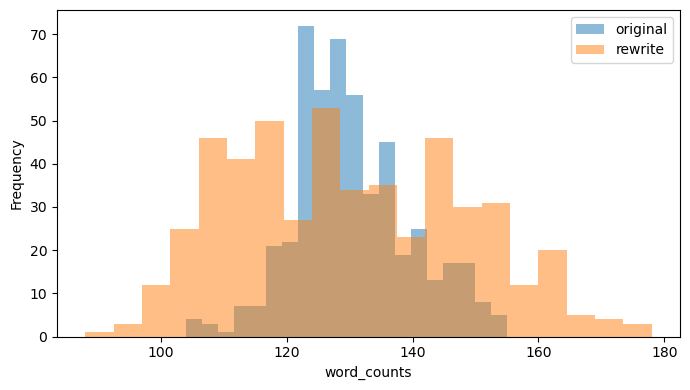

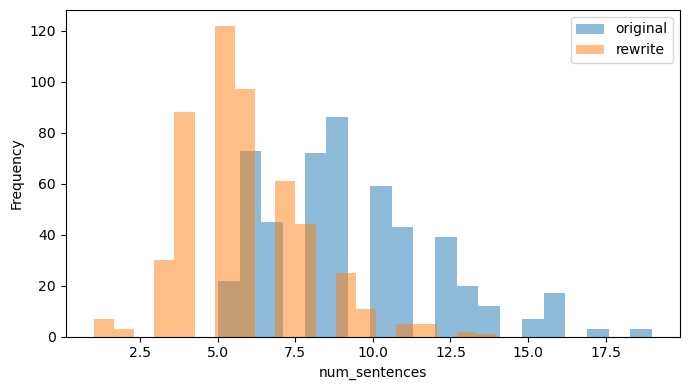

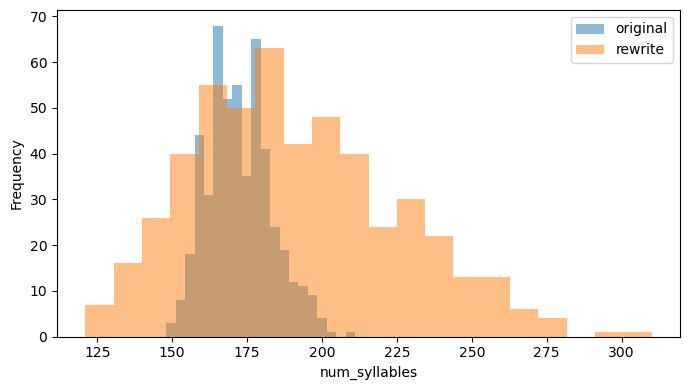

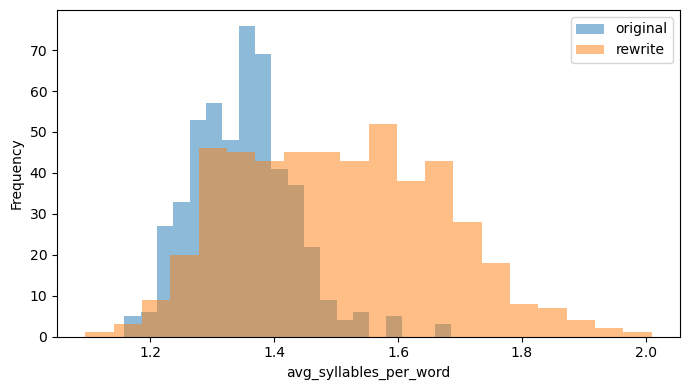

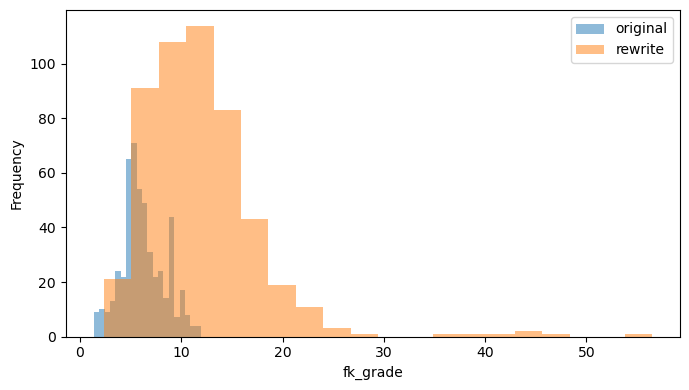

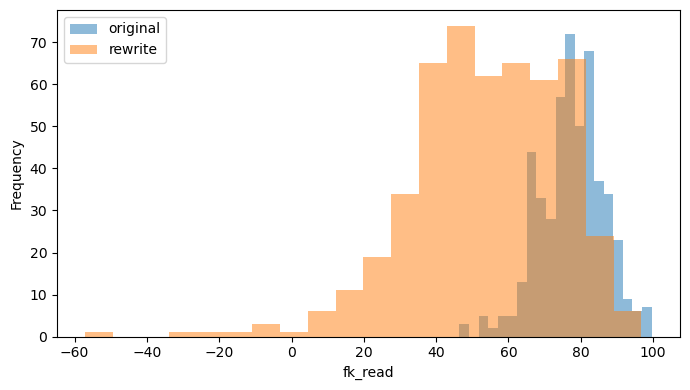

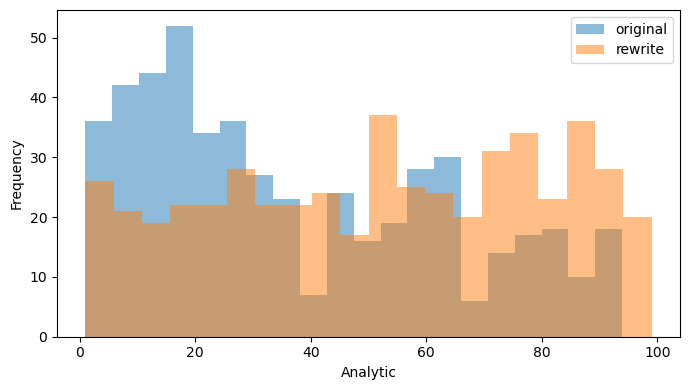

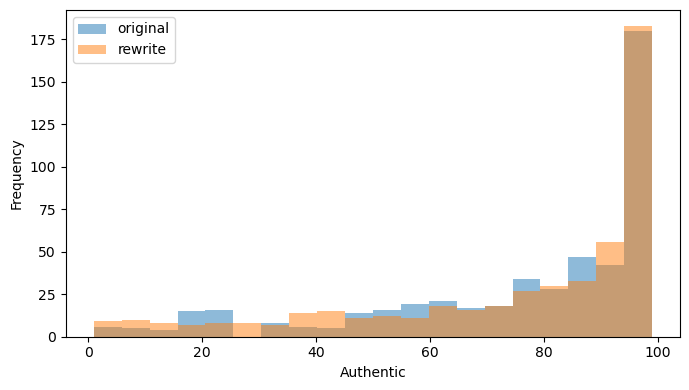

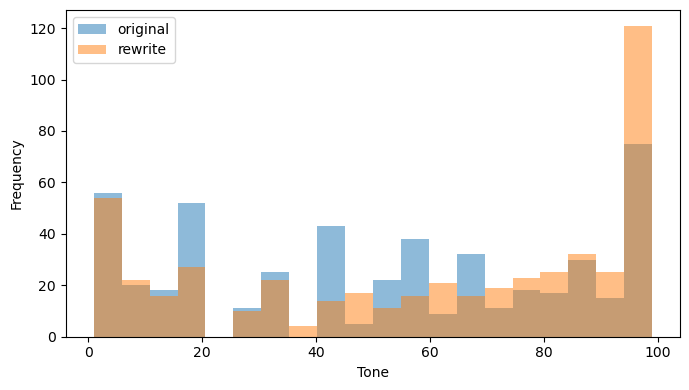

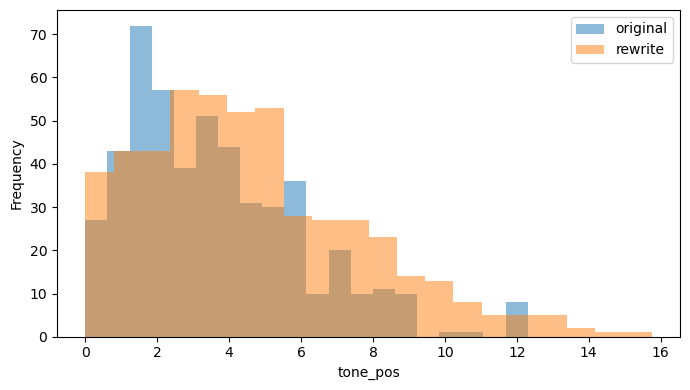

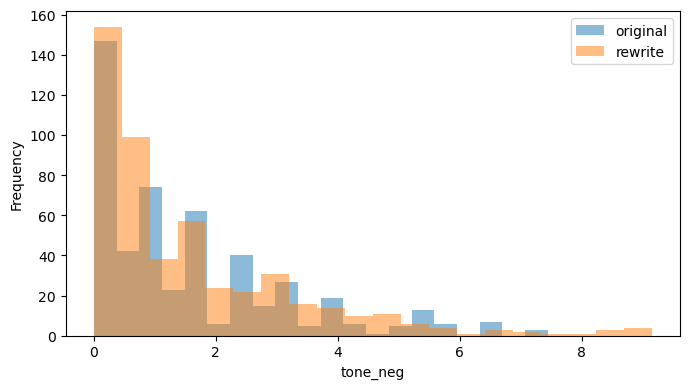

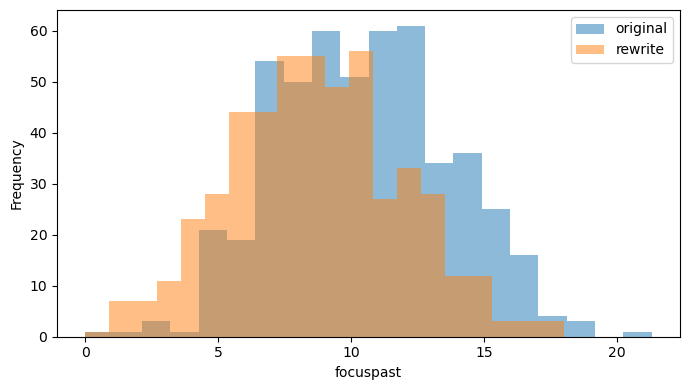

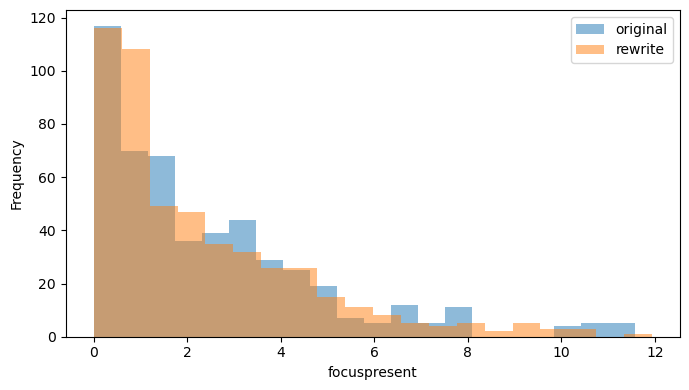

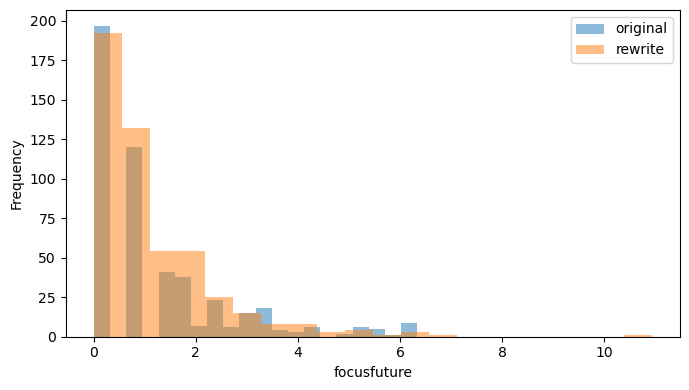

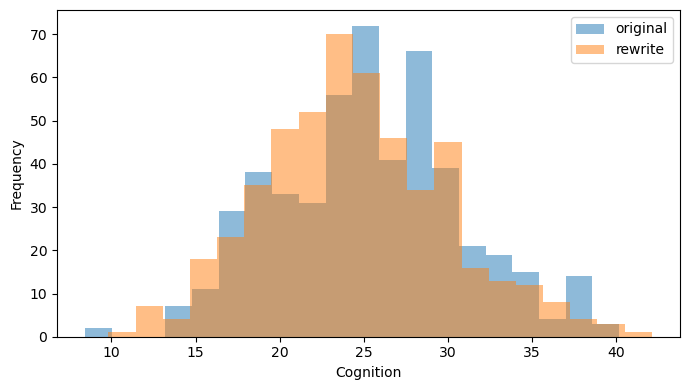

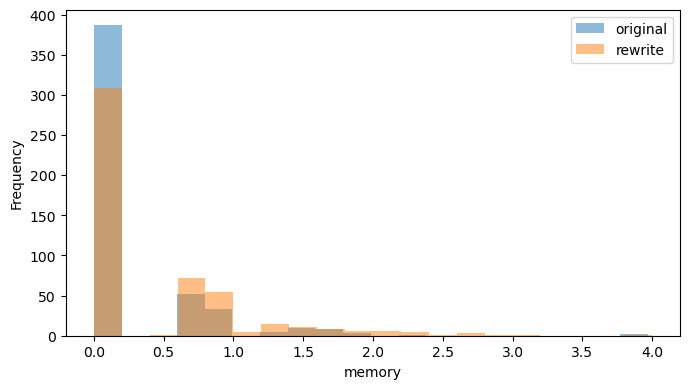

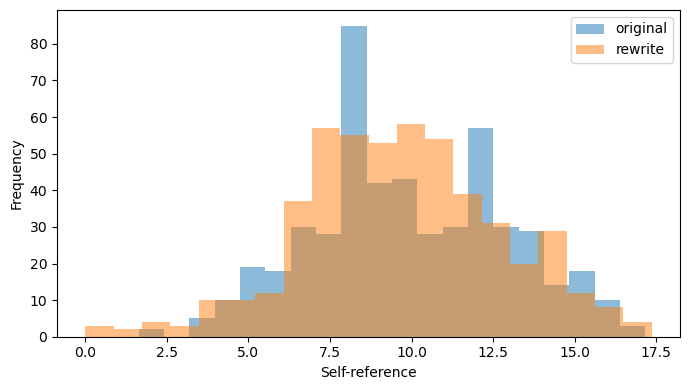

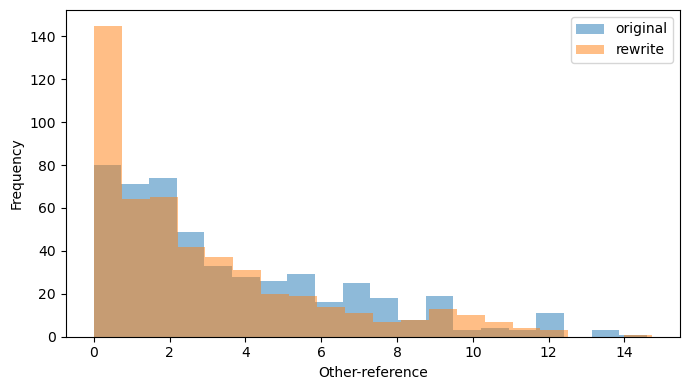

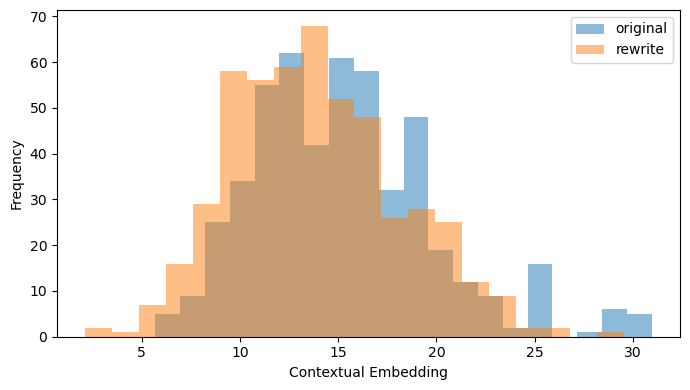

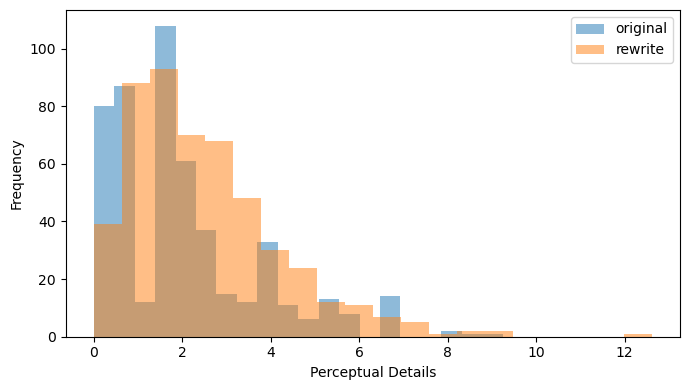

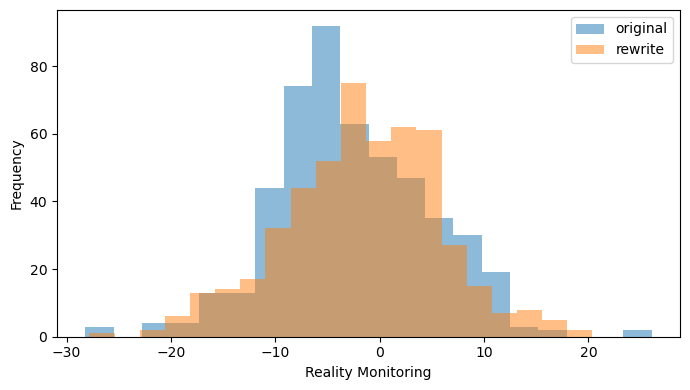

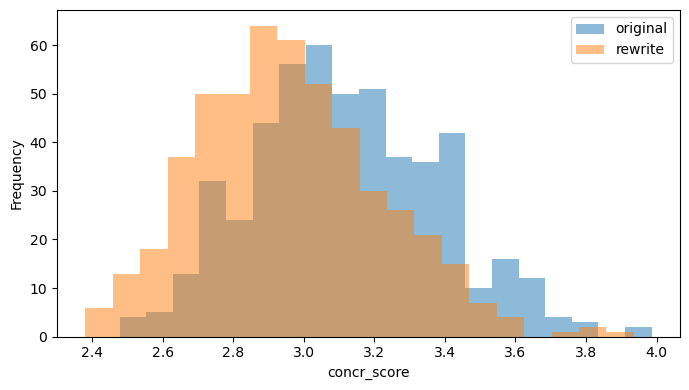

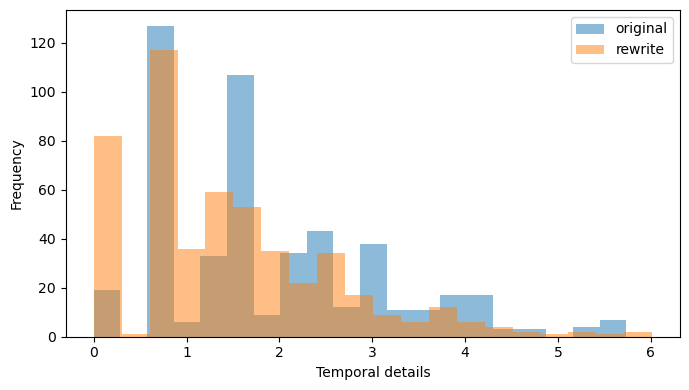

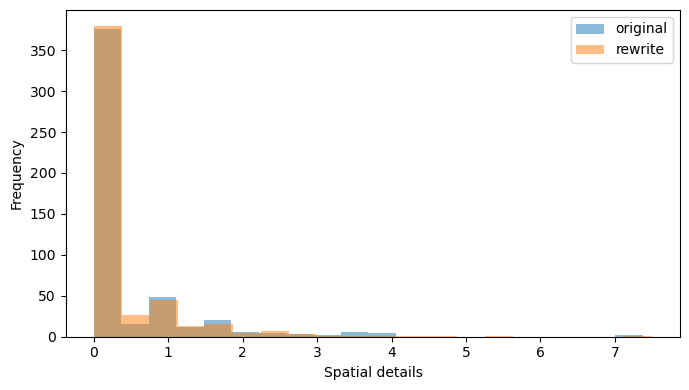

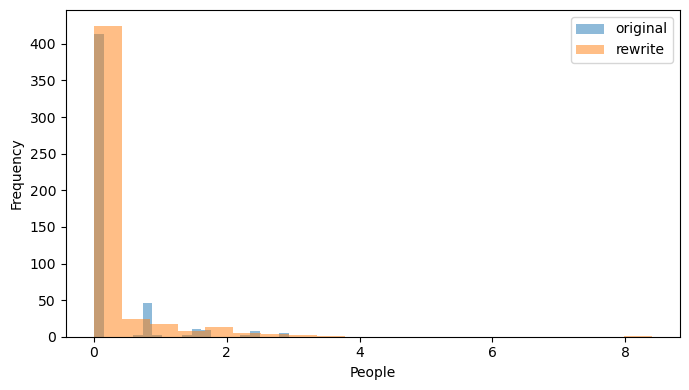

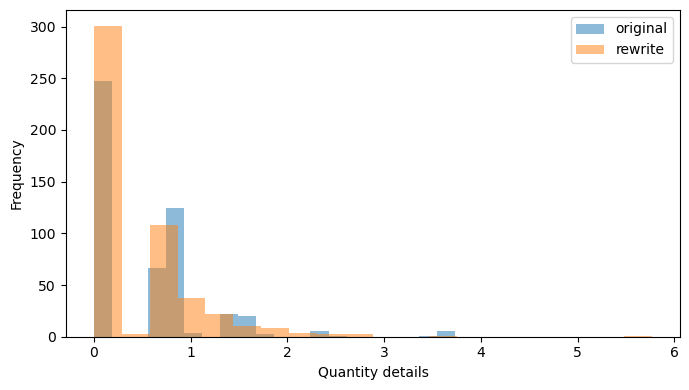

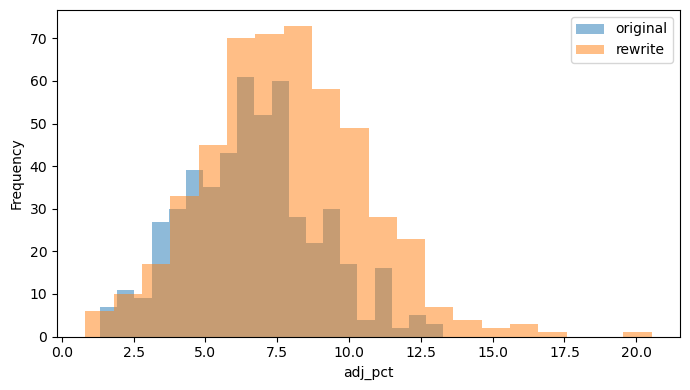

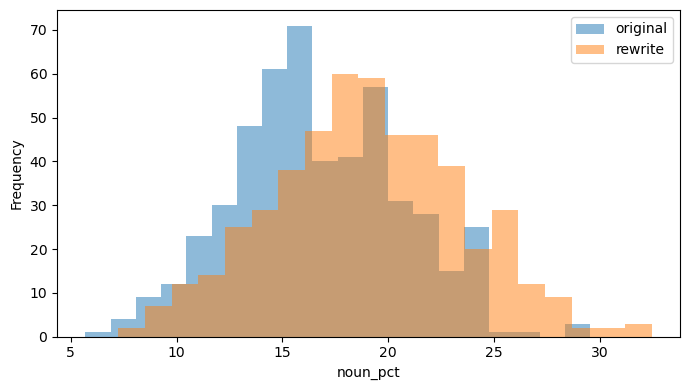

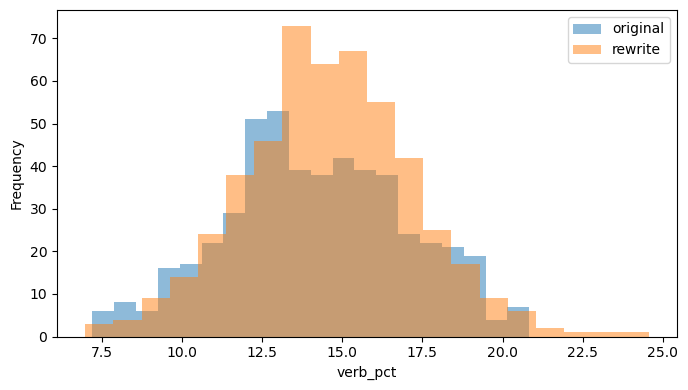

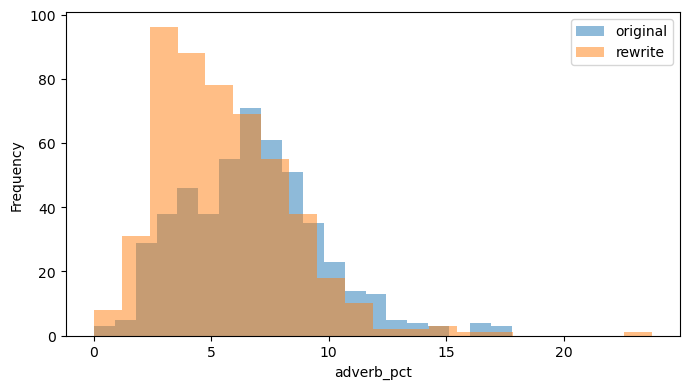

In [21]:
# Quick histogram overlays per feature (legacy-style visual check)
for feature in scoring_df_o.columns:
    plt.figure(figsize=(7, 4))
    scoring_df_o[feature].plot.hist(alpha=0.5, bins=20, label="original")
    scoring_df_r[feature].plot.hist(alpha=0.5, bins=20, label="rewrite")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.legend()
    plt.tight_layout()
    plt.show()

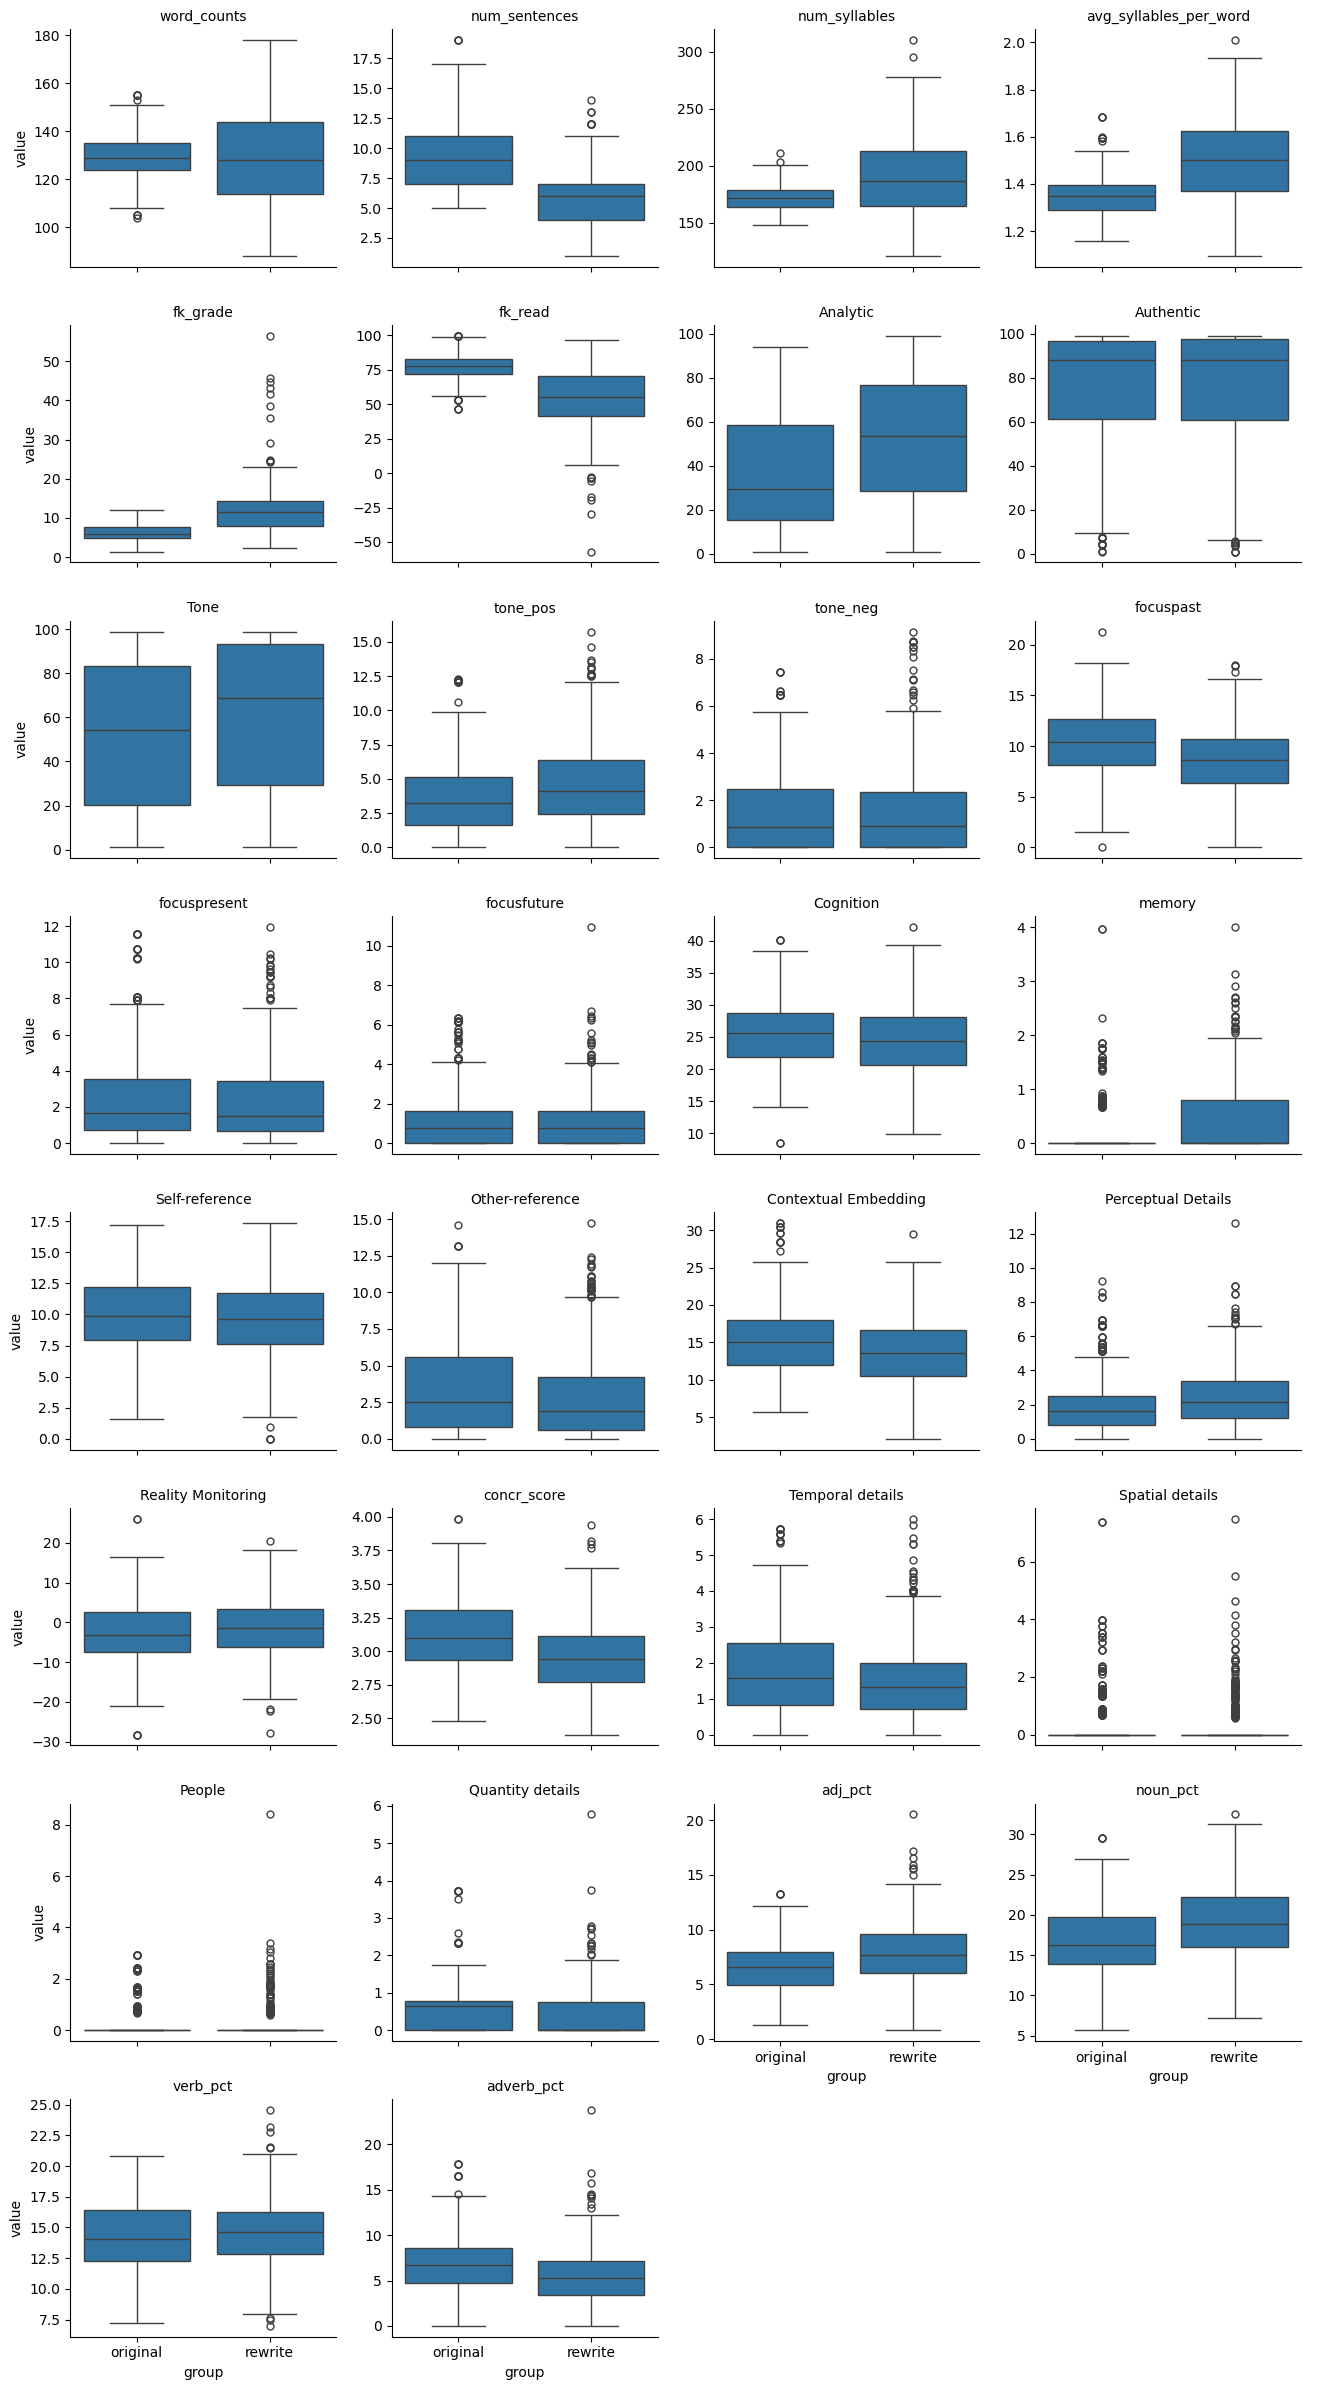

In [22]:
# Boxplot comparison for all features (faceted for readability)
melted = scoring_df.melt(id_vars=["text_type"], var_name="feature", value_name="value")

g = sns.catplot(
    data=melted,
    x="text_type",
    y="value",
    col="feature",
    col_wrap=4,
    kind="box",
    sharey=False,
    height=3,
    aspect=1.1
)
g.set_titles("{col_name}")
g.set_axis_labels("group", "value")
plt.show()

In [28]:
def statistic(x, y, axis):
    return np.mean(x, axis=axis) - np.mean(y, axis=axis)

def bootstrap_cles_ci(x, y, alpha=0.05, n_boot=1000):
    boot_cles = []
    x = np.asarray(x)
    y = np.asarray(y)
    for _ in range(n_boot):
        sample_x = np.random.choice(x, size=len(x), replace=True)
        sample_y = np.random.choice(y, size=len(y), replace=True)
        cles = pg.compute_effsize(sample_x, sample_y, eftype="CLES")
        boot_cles.append(cles)
    lower = np.percentile(boot_cles, 100 * (alpha / 2))
    upper = np.percentile(boot_cles, 100 * (1 - alpha / 2))
    return round(float(lower), 3), round(float(upper), 3)

def cohen_d_and_ci(x, y, confidence=0.95):
    d = pg.compute_effsize(x, y, paired=False, eftype="cohen")
    ci_low, ci_high = pg.compute_esci(
        stat=d, nx=len(x), ny=len(y), paired=False, eftype="cohen", confidence=confidence
    )
    return float(d), (float(ci_low), float(ci_high))

stats = []
p_values = []
cles_scores = []
cles_cis = []
cohens_d_scores = []
cohens_d_cis = []

for col in scoring_df_o.columns:
    x = scoring_df_o[col].to_numpy()
    y = scoring_df_r[col].to_numpy()
    
    # Remove NaN values
    x_clean = x[~np.isnan(x)]
    y_clean = y[~np.isnan(y)]
    
    # Skip if insufficient data after NaN removal
    if len(x_clean) < 2 or len(y_clean) < 2:
        stats.append(np.nan)
        p_values.append(np.nan)
        cles_scores.append(np.nan)
        cles_cis.append((np.nan, np.nan))
        cohens_d_scores.append(np.nan)
        cohens_d_cis.append((np.nan, np.nan))
        continue

    res = permutation_test((x_clean, y_clean), statistic, vectorized=True, n_resamples=10000)
    stats.append(float(res.statistic))
    p_values.append(float(res.pvalue))

    cles = pg.compute_effsize(x_clean, y_clean, eftype="CLES")
    cles_scores.append(float(cles))
    cles_cis.append(bootstrap_cles_ci(x_clean, y_clean))

    cohens_d, cohens_d_ci = cohen_d_and_ci(x_clean, y_clean)
    cohens_d_scores.append(cohens_d)
    cohens_d_cis.append(cohens_d_ci)

null_h_rej, corrected_p_values, _, _ = multipletests(p_values, alpha=0.05, method="holm")

perm_df = pd.DataFrame({
    "feature": scoring_df_o.columns,
    "stat": stats,
    "p_value": p_values,
    "corrected_p_value": corrected_p_values,
    "effect_size_cles": cles_scores,
    "cles_95%_CI": cles_cis,
    "effect_size_cohens_d": cohens_d_scores,
    "cohens_d_95%_CI": cohens_d_cis,
    "null_h_rejected": null_h_rej
})
perm_df["significance"] = ["*" if x else "-" for x in perm_df["null_h_rejected"]]
perm_df = perm_df.sort_values(["null_h_rejected", "effect_size_cles"], ascending=False)
perm_df.head(40)

,feature,stat,p_value,corrected_p_value,effect_size_cles,cles_95%_CI,effect_size_cohens_d,cohens_d_95%_CI,null_h_rejected,significance
5,fk_read,23.469218,0.000200,0.005999,0.855925,"(0.831, 0.88)",1.478602,"(1.34, 1.62)",True,*
1,num_sentences,3.475050,0.000200,0.005999,0.851560,"(0.828, 0.874)",1.412562,"(1.27, 1.55)",True,*
21,concr_score,0.162811,0.000200,0.005999,0.670687,"(0.638, 0.703)",0.617723,"(0.49, 0.74)",True,*
11,focuspast,1.754271,0.000200,0.005999,0.646860,"(0.611, 0.683)",0.543688,"(0.42, 0.67)",True,*
29,adverb_pct,1.238944,0.000200,0.005999,0.628924,"(0.595, 0.663)",0.426406,"(0.3, 0.55)",True,*
22,Temporal details,0.478151,0.000200,0.005999,0.613974,"(0.578, 0.646)",0.408269,"(0.28, 0.53)",True,*
18,Contextual Embedding,1.402655,0.000200,0.005999,0.581693,"(0.55, 0.615)",0.313907,"(0.19, 0.44)",True,*
17,Other-reference,0.643393,0.001600,0.020798,0.565018,"(0.53, 0.599)",0.205480,"(0.08, 0.33)",True,*
8,Tone,-8.209278,0.000200,0.005999,0.423529,"(0.389, 0.46)",-0.241611,"(-0.37, -0.12)",True,*
15,memory,-0.191397,0.000200,0.005999,0.419126,"(0.392, 0.448)",-0.329850,"(-0.45, -0.21)",True,*


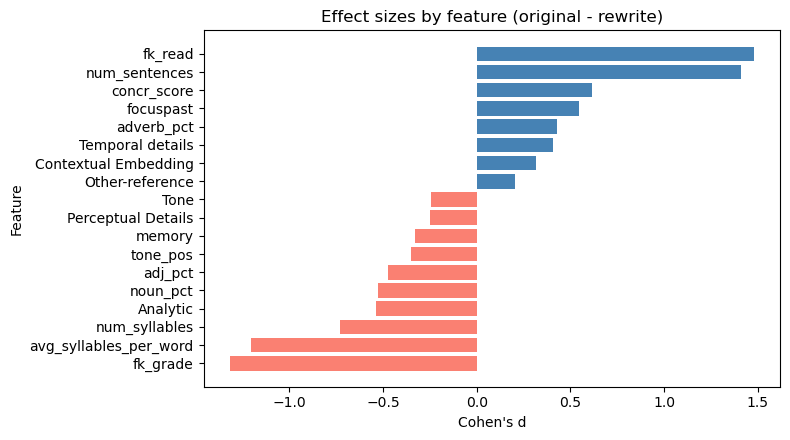

In [29]:
# Cohen's d chart for significant features
perm_df_selected = perm_df[perm_df["null_h_rejected"]].copy()
perm_df_sorted = perm_df_selected.sort_values("effect_size_cohens_d", ascending=True)

if perm_df_sorted.empty:
    print("No significant features after Holm correction.")
else:
    fig, ax = plt.subplots(figsize=(8, max(4, 0.25 * len(perm_df_sorted))))
    colors = ["steelblue" if stat > 0 else "salmon" for stat in perm_df_sorted["stat"]]
    ax.barh(perm_df_sorted["feature"], perm_df_sorted["effect_size_cohens_d"], color=colors)
    ax.set_xlabel("Cohen's d")
    ax.set_ylabel("Feature")
    ax.set_title("Effect sizes by feature (original - rewrite)")
    plt.tight_layout()
    plt.show()

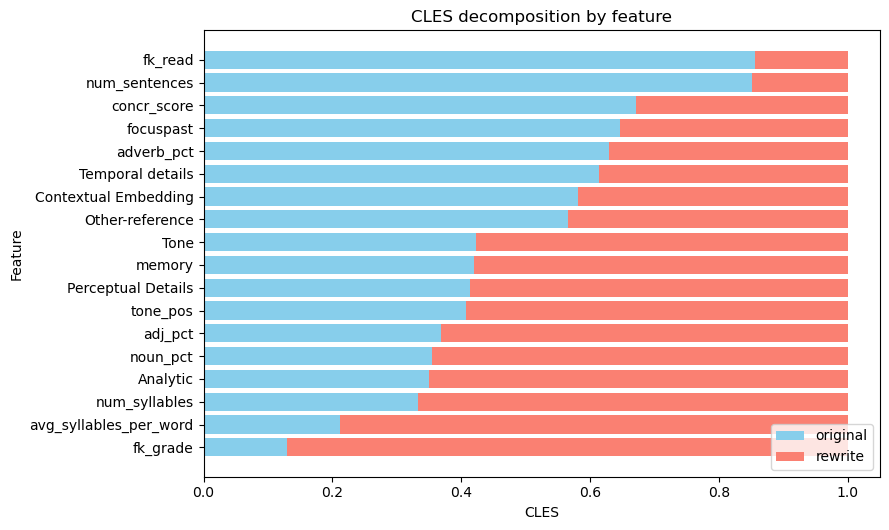

In [30]:
# CLES stacked chart for significant features
perm_df_selected = perm_df[perm_df["null_h_rejected"]].copy()
perm_df_sorted = perm_df_selected.sort_values("effect_size_cles", ascending=True)

if perm_df_sorted.empty:
    print("No significant features after Holm correction.")
else:
    perm_df_sorted["one_minus_cles"] = 1 - perm_df_sorted["effect_size_cles"]
    fig, ax = plt.subplots(figsize=(9, max(4, 0.3 * len(perm_df_sorted))))
    ax.barh(
        perm_df_sorted["feature"],
        perm_df_sorted["effect_size_cles"],
        color="skyblue",
        label="original"
    )
    ax.barh(
        perm_df_sorted["feature"],
        perm_df_sorted["one_minus_cles"],
        left=perm_df_sorted["effect_size_cles"],
        color="salmon",
        label="rewrite"
    )
    ax.set_xlabel("CLES")
    ax.set_ylabel("Feature")
    ax.set_title("CLES decomposition by feature")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

## Feature Analysis by Attack Modality

Perform statistical tests and effect size calculations for each attack modality separately.


In [32]:
# Get unique attack modalities and run analysis for each
modalities = sorted(scoring_with_keys['attack_modality'].dropna().unique())
print(f"Attack modalities found: {modalities}")

# Store results for each modality
modality_results = {}

for modality in modalities:
    print(f"\n{'='*60}")
    print(f"Attack Modality: {modality}")
    print(f"{'='*60}")
    
    # Filter data for this modality
    mod_data = scoring_with_keys[scoring_with_keys['attack_modality'] == modality]
    mod_scoring = scoring_df[scoring_with_keys['attack_modality'] == modality]
    
    # Split by text_type
    mod_orig = mod_scoring[mod_scoring['text_type'] == 'original'].drop('text_type', axis=1)
    mod_rewr = mod_scoring[mod_scoring['text_type'] == 'rewrite'].drop('text_type', axis=1)
    
    print(f"Original texts: {len(mod_orig)}, Rewrite texts: {len(mod_rewr)}")
    
    if len(mod_orig) == 0 or len(mod_rewr) == 0:
        print("Skipping: insufficient data for this modality")
        continue
    
    # Run permutation tests and effect sizes
    stats = []
    p_values = []
    cles_scores = []
    cohens_d_scores = []
    
    for col in mod_orig.columns:
        x = mod_orig[col].to_numpy()
        y = mod_rewr[col].to_numpy()
        
        # Remove NaN values
        x_clean = x[~np.isnan(x)]
        y_clean = y[~np.isnan(y)]
        
        # Skip if insufficient data after NaN removal
        if len(x_clean) < 2 or len(y_clean) < 2:
            stats.append(np.nan)
            p_values.append(np.nan)
            cles_scores.append(np.nan)
            cohens_d_scores.append(np.nan)
            continue
        
        res = permutation_test((x_clean, y_clean), statistic, vectorized=True, n_resamples=10000)
        stats.append(float(res.statistic))
        p_values.append(float(res.pvalue))
        
        cles = pg.compute_effsize(x_clean, y_clean, eftype="CLES")
        cles_scores.append(float(cles))
        
        cohens_d = pg.compute_effsize(x_clean, y_clean, paired=False, eftype="cohen")
        cohens_d_scores.append(cohens_d)
    
    # Handle NaN values in p_values for multipletests
    p_values_array = np.array(p_values)
    valid_mask = ~np.isnan(p_values_array)
    
    null_h_rej = np.full(len(p_values), False)
    corrected_p_values = np.array(p_values)
    
    if valid_mask.sum() > 0:
        rej_valid, corr_valid, _, _ = multipletests(p_values_array[valid_mask], alpha=0.05, method="holm")
        null_h_rej[valid_mask] = rej_valid
        corrected_p_values[valid_mask] = corr_valid
    
    mod_results = pd.DataFrame({
        "feature": mod_orig.columns,
        "stat": stats,
        "p_value": p_values,
        "corrected_p_value": corrected_p_values,
        "effect_size_cles": cles_scores,
        "effect_size_cohens_d": cohens_d_scores,
        "null_h_rejected": null_h_rej
    })
    mod_results["significance"] = ["*" if x else "-" for x in mod_results["null_h_rejected"]]
    mod_results = mod_results.sort_values(["null_h_rejected", "effect_size_cles"], ascending=False)
    
    modality_results[modality] = mod_results
    
    print(f"\nSignificant features (Holm corrected p < 0.05): {mod_results['null_h_rejected'].sum()}")
    display(mod_results.head(30))


Attack modalities found: ['human', 'llm']

Attack Modality: human
Original texts: 223, Rewrite texts: 223

Significant features (Holm corrected p < 0.05): 3


,feature,stat,p_value,corrected_p_value,effect_size_cles,effect_size_cohens_d,null_h_rejected,significance
1,num_sentences,2.434978,0.000200,0.005999,0.737950,0.929736,True,*
5,fk_read,9.677306,0.000200,0.005999,0.691377,0.640132,True,*
4,fk_grade,-3.170924,0.000200,0.005999,0.271039,-0.618527,True,*
0,word_counts,3.484305,0.005799,0.150785,0.573750,0.263610,False,-
22,Temporal details,0.268131,0.022198,0.532747,0.565947,0.224939,False,-
2,num_syllables,1.313901,0.484152,1.000000,0.556366,0.068165,False,-
11,focuspast,0.769821,0.016598,0.414959,0.555491,0.226920,False,-
21,concr_score,0.027233,0.276972,1.000000,0.524965,0.103584,False,-
18,Contextual Embedding,0.590807,0.184182,1.000000,0.523970,0.125671,False,-
23,Spatial details,0.091827,0.259774,1.000000,0.514147,0.109261,False,-



Attack Modality: llm
Original texts: 278, Rewrite texts: 278

Significant features (Holm corrected p < 0.05): 22


,feature,stat,p_value,corrected_p_value,effect_size_cles,effect_size_cohens_d,null_h_rejected,significance
5,fk_read,34.532513,0.000200,0.005999,0.987915,3.004758,True,*
1,num_sentences,4.309353,0.000200,0.005999,0.943371,1.998769,True,*
21,concr_score,0.271565,0.000200,0.005999,0.781274,1.108686,True,*
29,adverb_pct,2.191629,0.000200,0.005999,0.726360,0.869155,True,*
11,focuspast,2.543957,0.000200,0.005999,0.721346,0.852943,True,*
22,Temporal details,0.646620,0.000200,0.005999,0.652632,0.562991,True,*
18,Contextual Embedding,2.053885,0.000200,0.005999,0.626449,0.489316,True,*
17,Other-reference,1.188058,0.000200,0.005999,0.617663,0.411565,True,*
14,Cognition,1.770360,0.000200,0.005999,0.591882,0.352500,True,*
25,Quantity details,0.207990,0.000200,0.005999,0.589533,0.334942,True,*


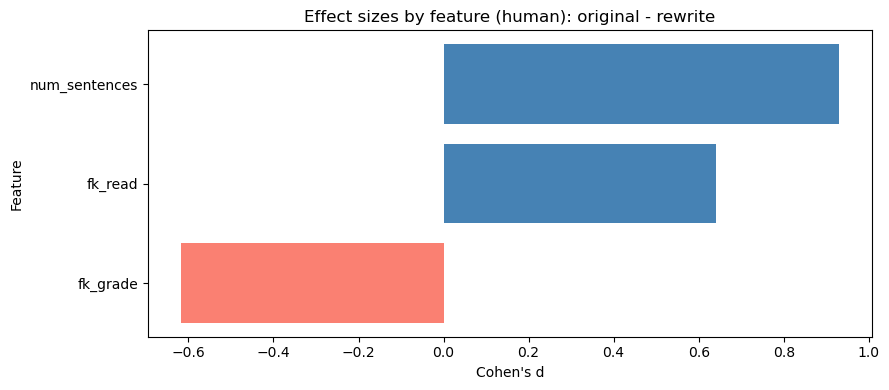

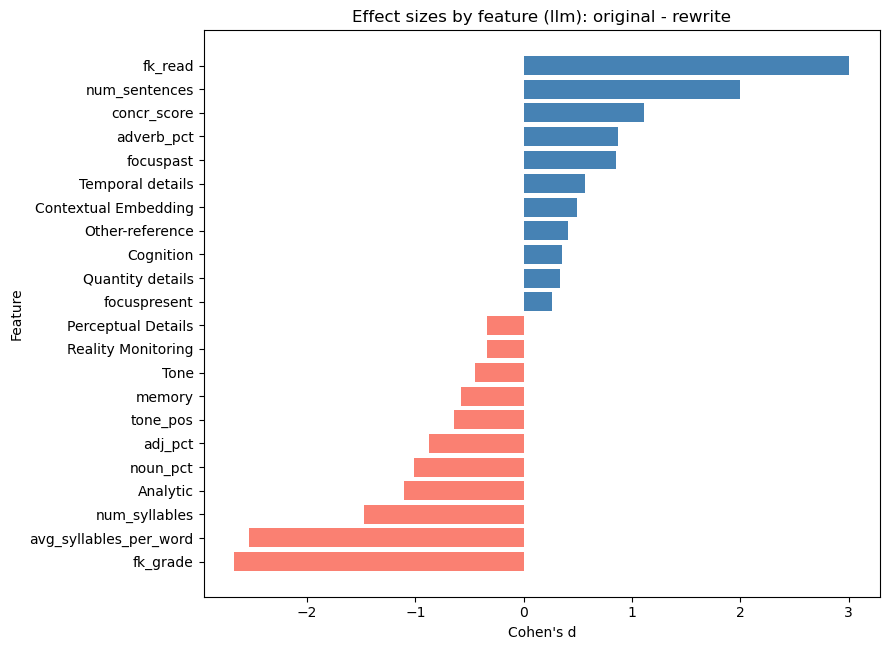

In [33]:
# Cohen's d comparison chart for each modality
for modality in modalities:
    if modality not in modality_results:
        continue
    
    mod_df = modality_results[modality]
    mod_df_sig = mod_df[mod_df['null_h_rejected']].copy()
    
    if mod_df_sig.empty:
        print(f"\n{modality}: No significant features after Holm correction.")
        continue
    
    mod_df_sorted = mod_df_sig.sort_values('effect_size_cohens_d', ascending=True)
    
    fig, ax = plt.subplots(figsize=(9, max(4, 0.3 * len(mod_df_sorted))))
    colors = ["steelblue" if stat > 0 else "salmon" for stat in mod_df_sorted["stat"]]
    ax.barh(mod_df_sorted["feature"], mod_df_sorted["effect_size_cohens_d"], color=colors)
    ax.set_xlabel("Cohen's d")
    ax.set_ylabel("Feature")
    ax.set_title(f"Effect sizes by feature ({modality}): original - rewrite")
    plt.tight_layout()
    plt.show()


In [34]:
# Summary comparison table: which features are significant per modality
all_features = set()
for mod_df in modality_results.values():
    all_features.update(mod_df[mod_df['null_h_rejected']]['feature'].tolist())

summary_table = pd.DataFrame(index=sorted(all_features))
for modality in modalities:
    if modality not in modality_results:
        continue
    mod_df = modality_results[modality]
    sig_features = set(mod_df[mod_df['null_h_rejected']]['feature'])
    summary_table[f'{modality}_significant'] = summary_table.index.isin(sig_features).astype(int)
    
    # Add Cohen's d values
    for idx in summary_table.index:
        if idx in mod_df['feature'].values:
            d_val = mod_df[mod_df['feature'] == idx]['effect_size_cohens_d'].values[0]
            summary_table.loc[idx, f'{modality}_cohens_d'] = round(d_val, 3)

print("\nSignificant Features by Attack Modality:")
display(summary_table)



Significant Features by Attack Modality:


,human_significant,human_cohens_d,llm_significant,llm_cohens_d
Analytic,0,0.012,1,-1.102
Cognition,0,-0.044,1,0.353
Contextual Embedding,0,0.126,1,0.489
Other-reference,0,-0.011,1,0.412
Perceptual Details,0,-0.132,1,-0.339
Quantity details,0,-0.025,1,0.335
Reality Monitoring,0,0.094,1,-0.340
Temporal details,0,0.225,1,0.563
Tone,0,0.012,1,-0.445
adj_pct,0,-0.010,1,-0.876


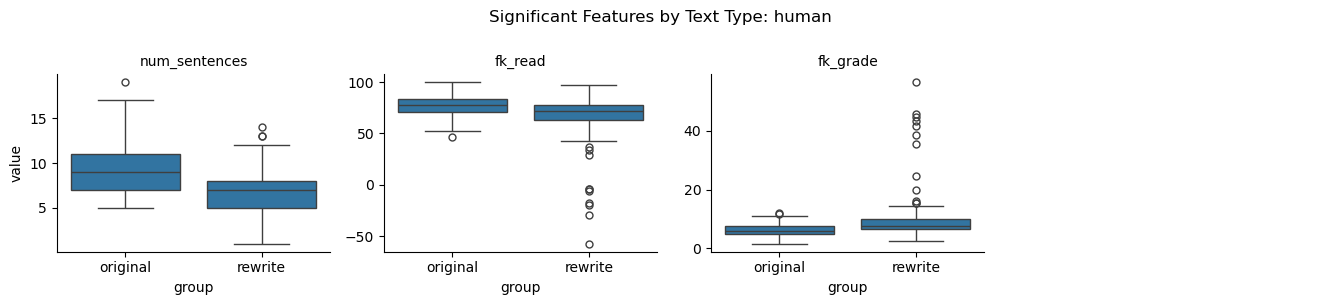

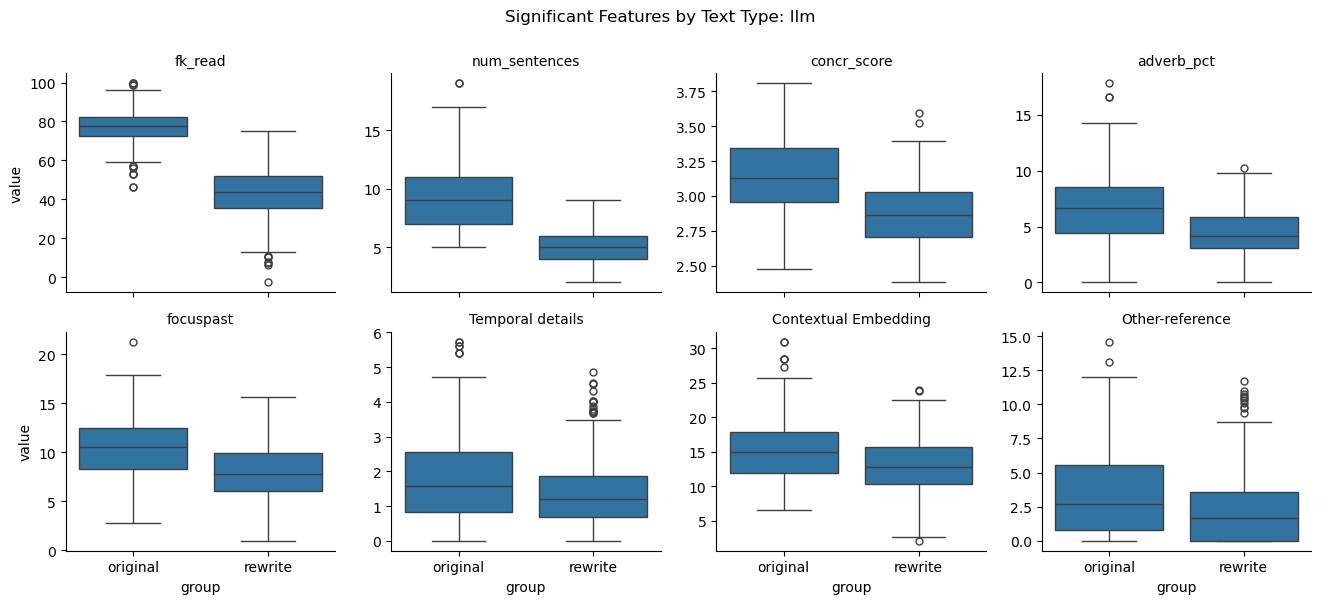

In [35]:
# Boxplots showing distributions by text_type within each modality (selected significant features)
for modality in modalities:
    if modality not in modality_results:
        continue
    
    mod_df = modality_results[modality]
    sig_features = mod_df[mod_df['null_h_rejected']]['feature'].tolist()
    
    if not sig_features:
        print(f"\n{modality}: No significant features to visualize.")
        continue
    
    # Get data for this modality
    mod_scoring_data = scoring_with_keys[scoring_with_keys['attack_modality'] == modality]
    mod_scoring_all = scoring_df[scoring_with_keys['attack_modality'] == modality]
    
    # Melt for plotting (limit to 8 significant features for readability)
    features_to_plot = sig_features[:8]
    plot_cols = ['text_type'] + features_to_plot
    plot_data = mod_scoring_all[plot_cols].copy()
    
    melted = plot_data.melt(id_vars=['text_type'], var_name='feature', value_name='value')
    
    g = sns.catplot(
        data=melted,
        x='text_type',
        y='value',
        col='feature',
        col_wrap=4,
        kind='box',
        sharey=False,
        height=3,
        aspect=1.1
    )
    g.set_titles("{col_name}")
    g.set_axis_labels("group", "value")
    fig = g.fig
    fig.suptitle(f"Significant Features by Text Type: {modality}", y=1.00)
    plt.tight_layout()
    plt.show()


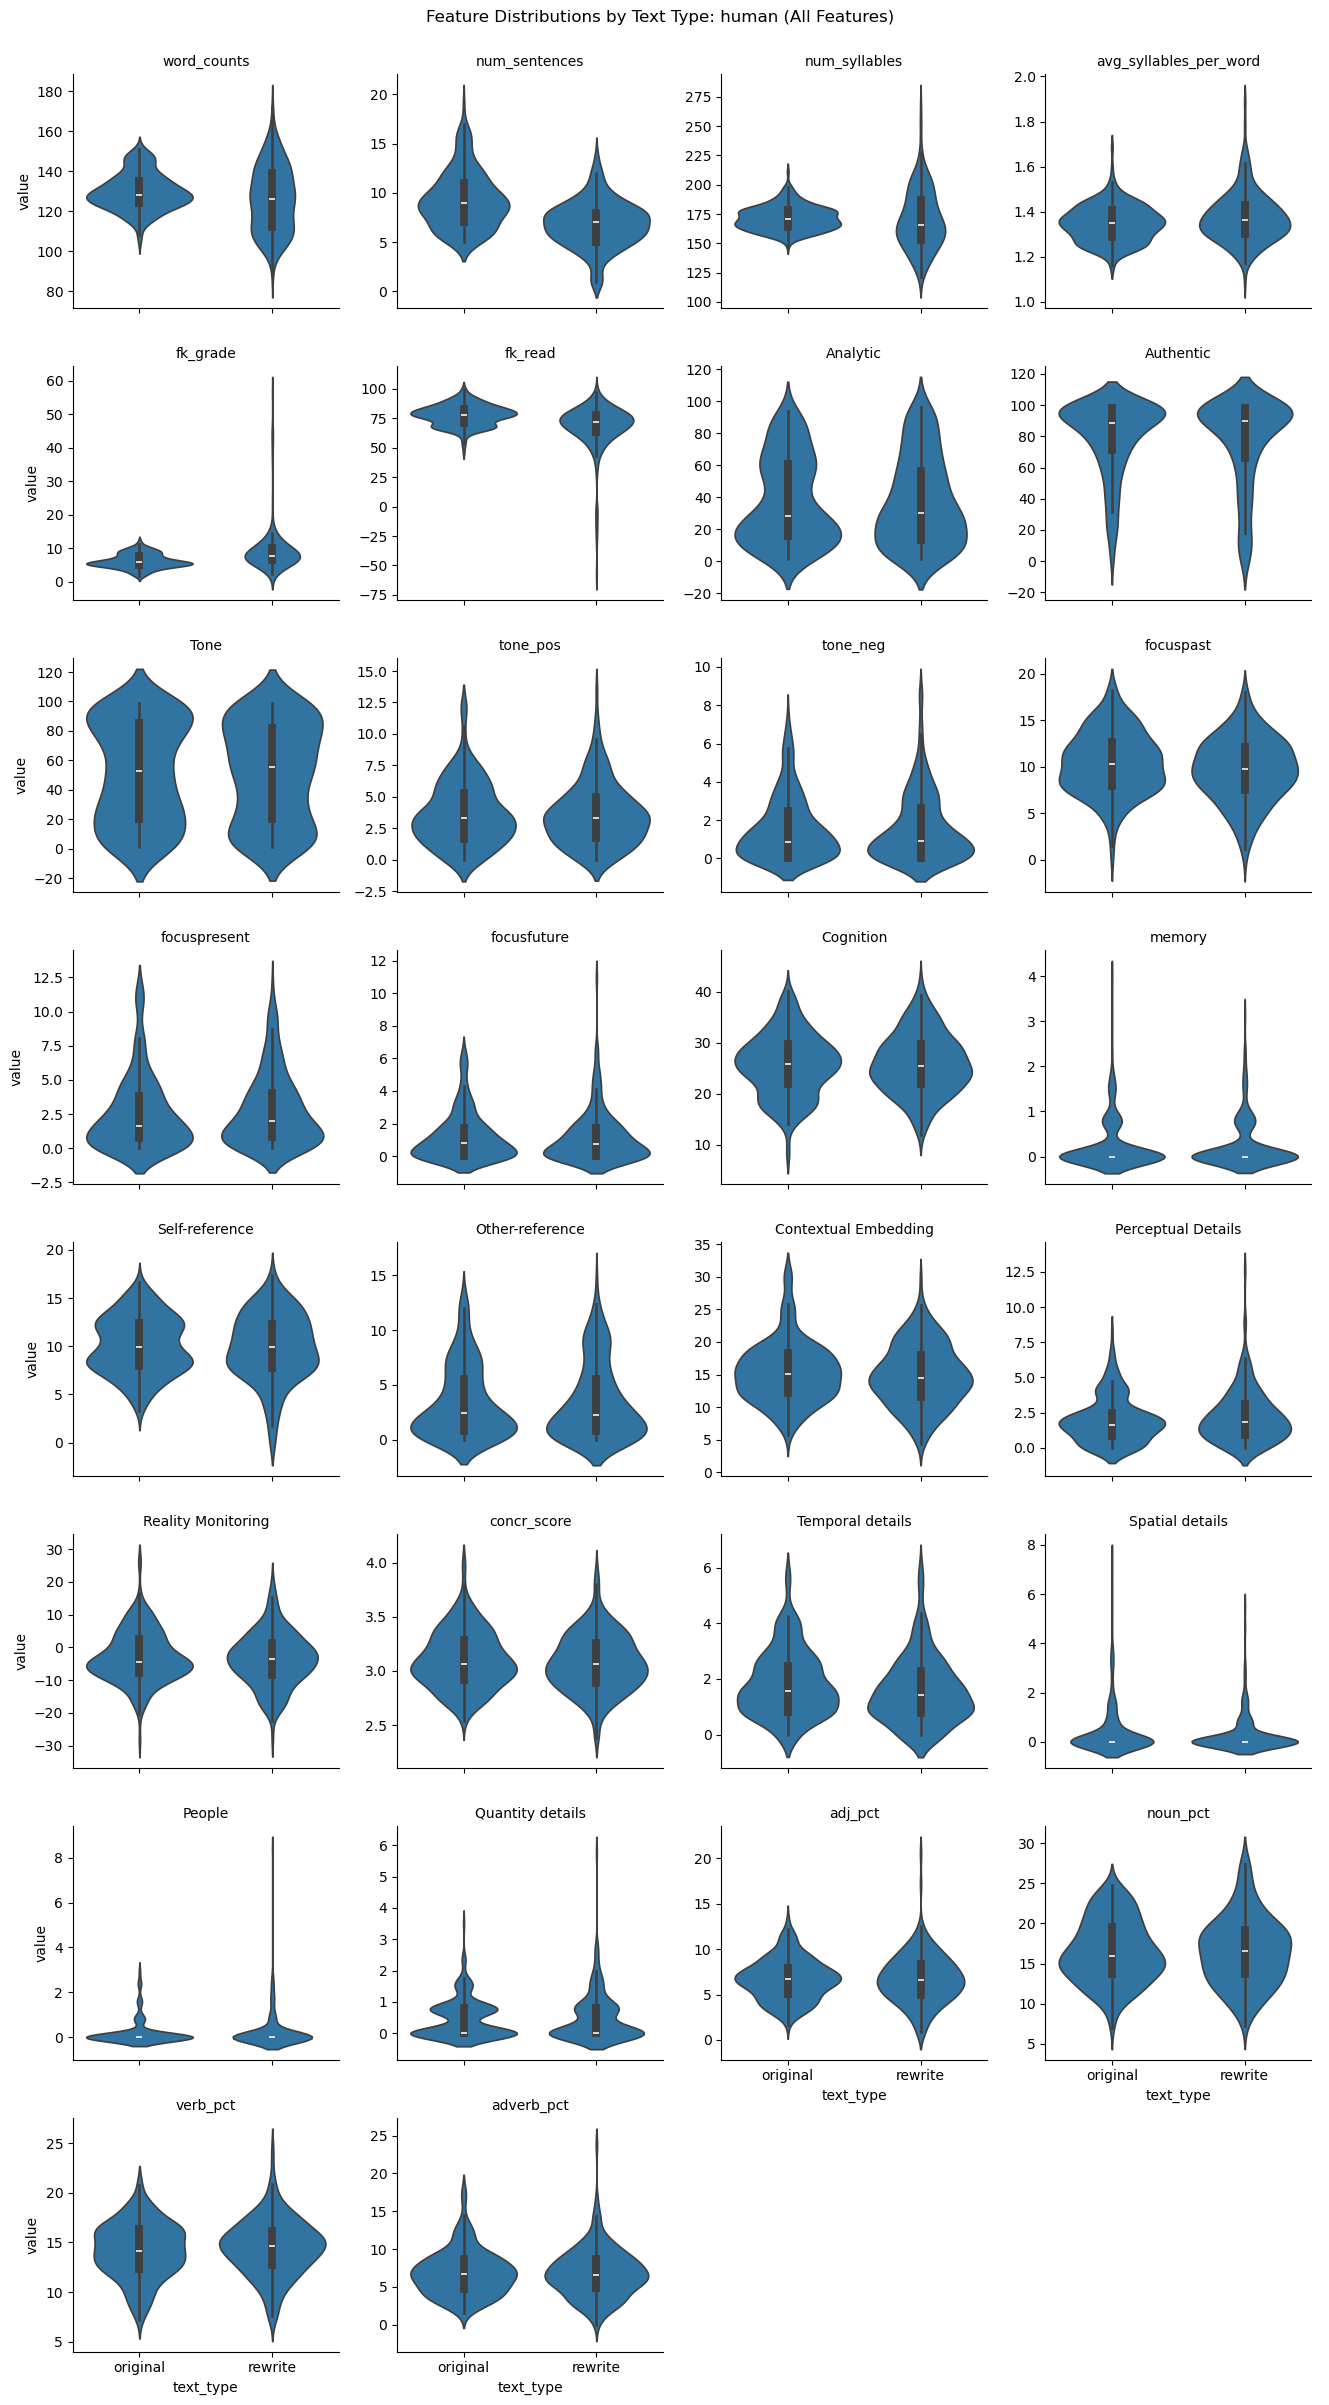

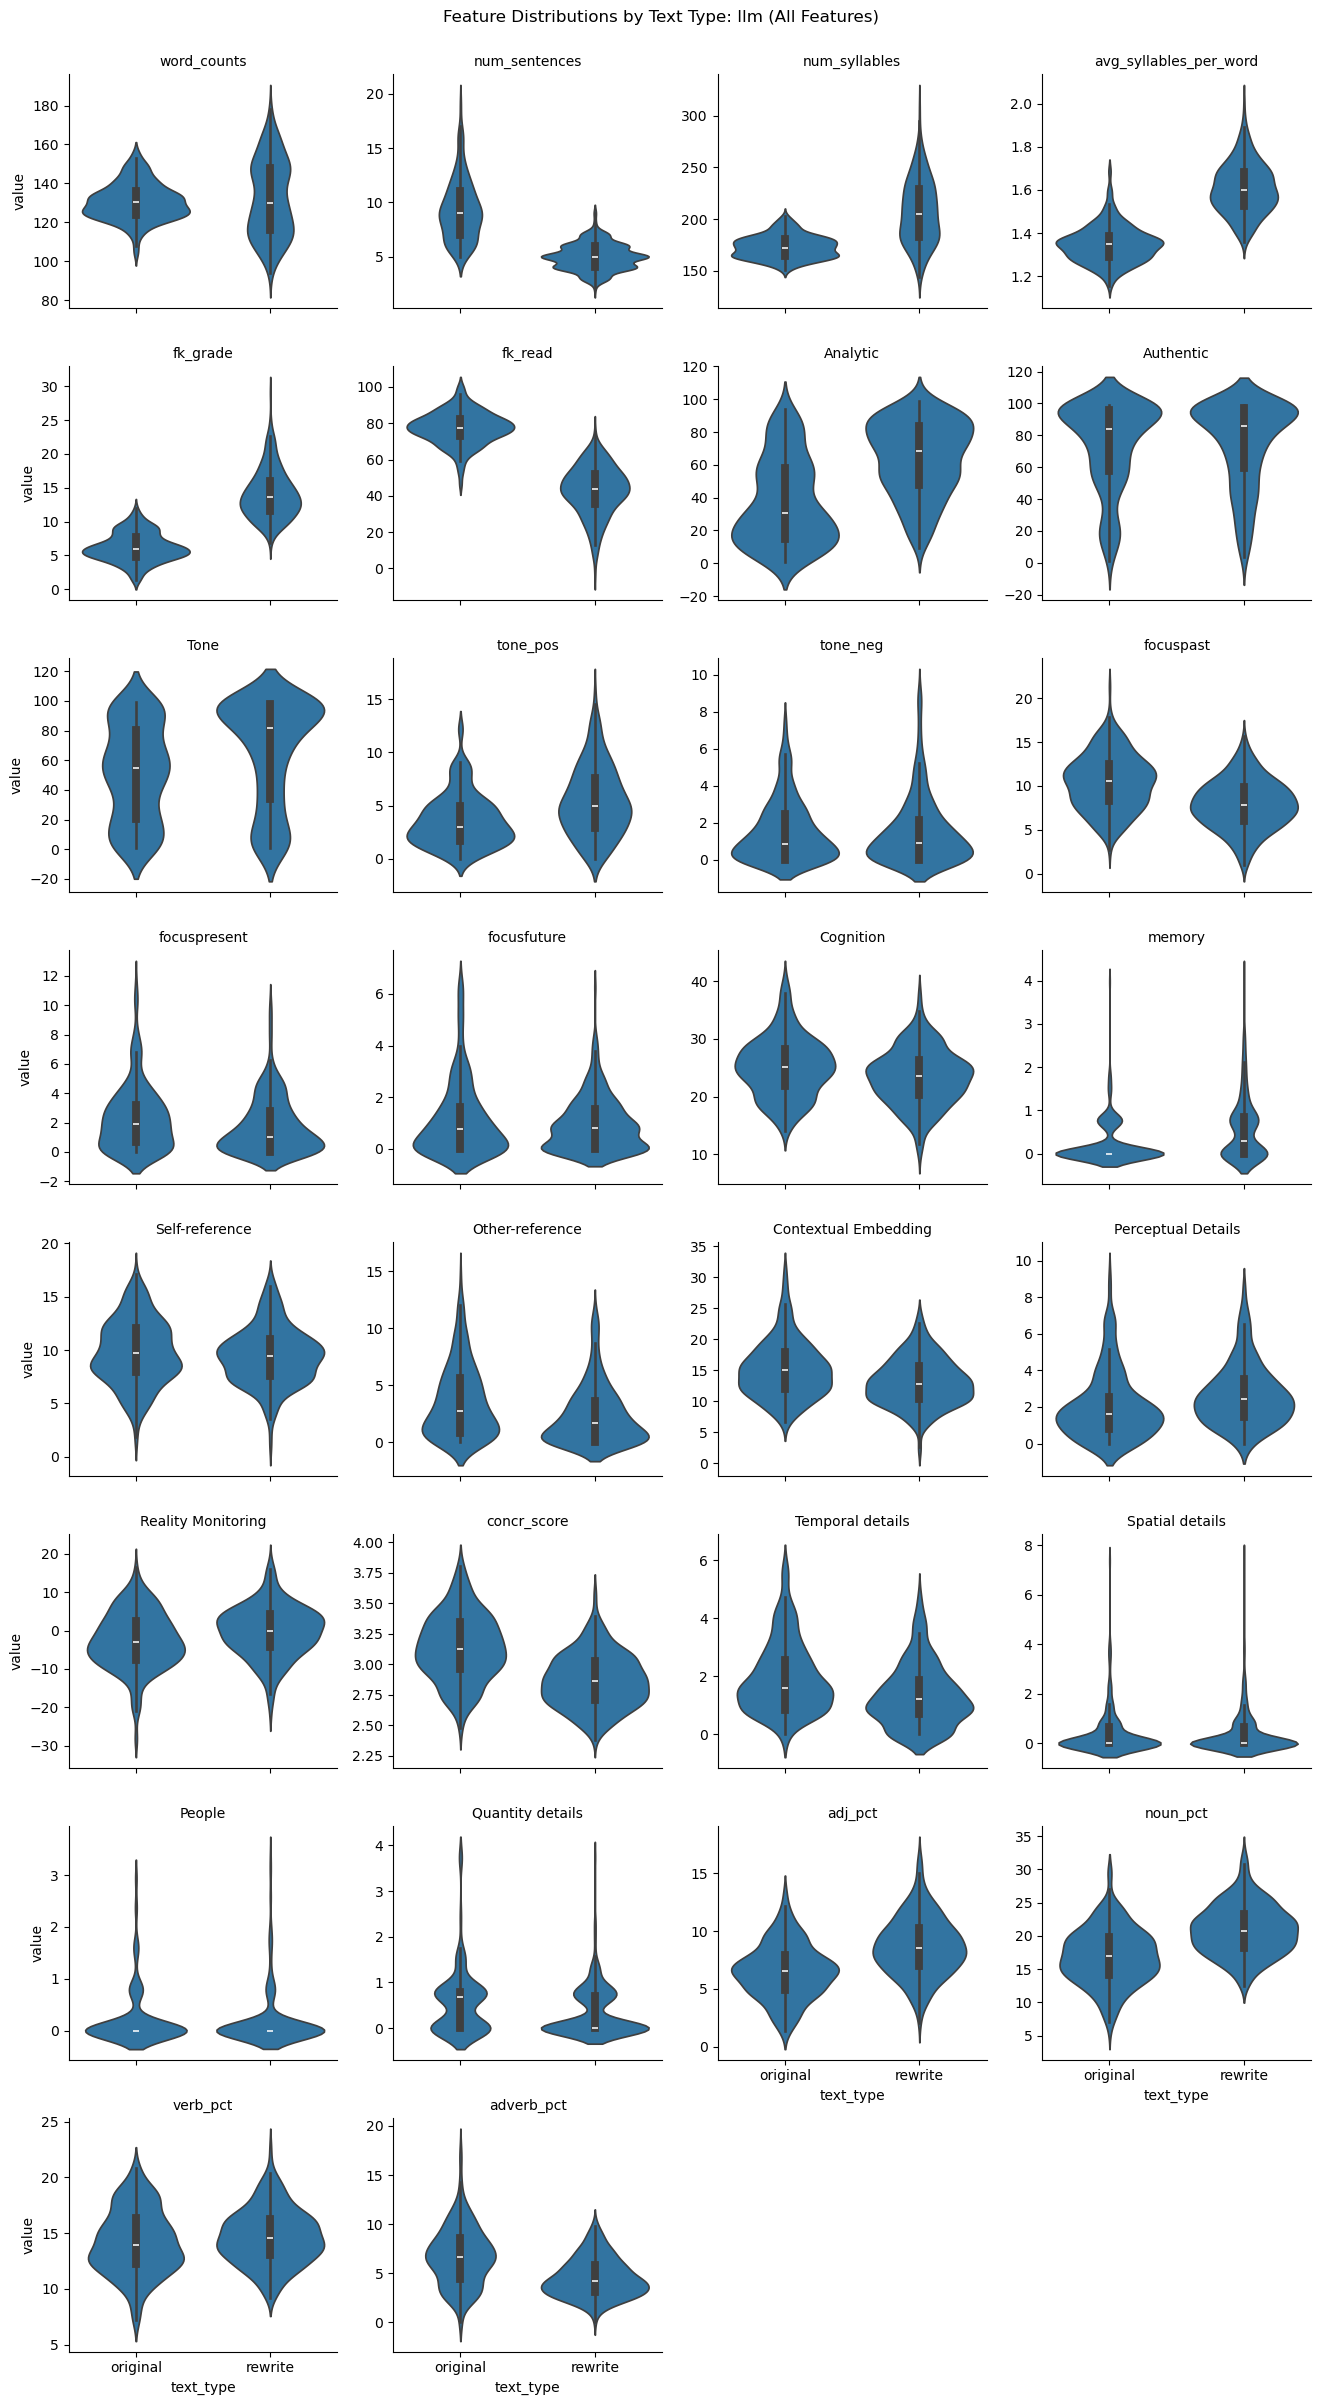

In [36]:
# Distribution overlap visualizations for each feature within each modality
for modality in modalities:
    if modality not in modality_results:
        continue
    
    # Get data for this modality
    mod_scoring_all = scoring_df[scoring_with_keys['attack_modality'] == modality]
    
    # Get all features (not just significant)
    features_list = [col for col in mod_scoring_all.columns if col != 'text_type']
    
    # Create violin plots for all features
    plot_cols = ['text_type'] + features_list
    plot_data = mod_scoring_all[plot_cols].copy()
    
    melted = plot_data.melt(id_vars=['text_type'], var_name='feature', value_name='value')
    
    g = sns.catplot(
        data=melted,
        x='text_type',
        y='value',
        col='feature',
        col_wrap=4,
        kind='violin',
        sharey=False,
        height=3,
        aspect=1.1
    )
    g.set_titles("{col_name}")
    g.set_axis_labels("text_type", "value")
    fig = g.fig
    fig.suptitle(f"Feature Distributions by Text Type: {modality} (All Features)", y=1.00)
    plt.tight_layout()
    plt.show()


## Feature Analysis by Modality × Original Veracity

For each combination of `attack_modality` (human / LLM) and `original_veracity` (Deceptive / Truthful), run permutation tests (Holm-corrected) and compute Cohen's d and CLES to compare **original** vs **rewrite** linguistic features.


In [38]:
# ── Run permutation tests + effect sizes for each modality × veracity combo ──
veracities  = sorted(scoring_with_keys['original_veracity'].dropna().unique())
modalities  = sorted(scoring_with_keys['attack_modality'].dropna().unique())

# Nested dict: veracity_results[modality][veracity] = results DataFrame
veracity_results = {m: {} for m in modalities}

feature_cols = [c for c in scoring_with_keys.columns
                if c not in ['rewrite_id', 'statement_id', 'topic_label',
                              'attack_modality', 'original_veracity', 'target_veracity',
                              'original_label', 'rewrite_label', 'asr', 'text_type',
                              'text', 'word_counts']]

for modality in modalities:
    for veracity in veracities:
        mask = (
            (scoring_with_keys['attack_modality'] == modality) &
            (scoring_with_keys['original_veracity'] == veracity)
        )
        subset = scoring_with_keys[mask]

        sub_orig = subset[subset['text_type'] == 'original'][feature_cols]
        sub_rewr = subset[subset['text_type'] == 'rewrite'][feature_cols]

        label = f"{modality} / {veracity}"
        print(f"\n{'='*65}")
        print(f"Modality: {modality.upper()}  |  Veracity: {veracity}")
        print(f"  Original: {len(sub_orig)}  Rewrite: {len(sub_rewr)}")
        print(f"{'='*65}")

        if len(sub_orig) < 5 or len(sub_rewr) < 5:
            print("  Skipping: insufficient data.")
            continue

        stats_list, pvals, cles_list, d_list = [], [], [], []

        for col in feature_cols:
            x = sub_orig[col].to_numpy()
            y = sub_rewr[col].to_numpy()
            x_c = x[~np.isnan(x)]
            y_c = y[~np.isnan(y)]

            if len(x_c) < 2 or len(y_c) < 2:
                stats_list.append(np.nan)
                pvals.append(np.nan)
                cles_list.append(np.nan)
                d_list.append(np.nan)
                continue

            res = permutation_test((x_c, y_c), statistic, vectorized=True, n_resamples=10000)
            stats_list.append(float(res.statistic))
            pvals.append(float(res.pvalue))
            cles_list.append(float(pg.compute_effsize(x_c, y_c, eftype='CLES')))
            d_list.append(float(pg.compute_effsize(x_c, y_c, paired=False, eftype='cohen')))

        pvals_arr  = np.array(pvals)
        valid_mask = ~np.isnan(pvals_arr)
        null_rej   = np.full(len(pvals), False)
        corr_pvals = pvals_arr.copy()

        if valid_mask.sum() > 0:
            rej_v, corr_v, _, _ = multipletests(pvals_arr[valid_mask], alpha=0.05, method='holm')
            null_rej[valid_mask]   = rej_v
            corr_pvals[valid_mask] = corr_v

        res_df = pd.DataFrame({
            'feature':             feature_cols,
            'stat':                stats_list,
            'p_value':             pvals,
            'corrected_p_value':   corr_pvals,
            'effect_size_cles':    cles_list,
            'effect_size_cohens_d': d_list,
            'null_h_rejected':     null_rej,
        })
        res_df['significance'] = ['*' if v else '-' for v in res_df['null_h_rejected']]
        res_df = res_df.sort_values(['null_h_rejected', 'effect_size_cles'], ascending=False)

        veracity_results[modality][veracity] = res_df

        n_sig = res_df['null_h_rejected'].sum()
        print(f"  Significant features (Holm p < 0.05): {n_sig}")
        display(res_df.head(20))



Modality: HUMAN  |  Veracity: Deceptive
  Original: 131  Rewrite: 131
  Significant features (Holm p < 0.05): 4


,feature,stat,p_value,corrected_p_value,effect_size_cles,effect_size_cohens_d,null_h_rejected,significance
0,num_sentences,3.603053,0.000200,0.005799,0.846396,1.383597,True,*
4,fk_read,12.499028,0.000200,0.005799,0.774314,0.868032,True,*
2,avg_syllables_per_word,-0.037399,0.001800,0.046795,0.411544,-0.396431,True,*
3,fk_grade,-4.028181,0.000200,0.005799,0.172775,-0.817961,True,*
1,num_syllables,2.641221,0.218778,1.000000,0.585776,0.150852,False,-
10,focuspast,0.637481,0.125187,1.000000,0.549560,0.188821,False,-
13,Cognition,0.912519,0.215978,1.000000,0.547171,0.153239,False,-
28,adverb_pct,0.371056,0.322768,1.000000,0.546472,0.119839,False,-
15,Self-reference,0.472901,0.214779,1.000000,0.536595,0.155411,False,-
8,tone_pos,0.266336,0.420558,1.000000,0.526601,0.101378,False,-



Modality: HUMAN  |  Veracity: Truthful
  Original: 92  Rewrite: 92
  Significant features (Holm p < 0.05): 0


,feature,stat,p_value,corrected_p_value,effect_size_cles,effect_size_cohens_d,null_h_rejected,significance
21,Temporal details,0.448456,0.024998,0.649935,0.617379,0.333812,False,-
24,Quantity details,0.136865,0.243576,1.000000,0.591623,0.170693,False,-
0,num_sentences,0.771739,0.027997,0.699930,0.576796,0.337350,False,-
19,Reality Monitoring,2.955435,0.015998,0.431957,0.576619,0.357164,False,-
10,focuspast,0.958261,0.050795,1.000000,0.567876,0.283738,False,-
4,fk_read,5.659420,0.012799,0.358364,0.561850,0.356946,False,-
5,Analytic,5.616304,0.176982,1.000000,0.560551,0.198508,False,-
17,Contextual Embedding,1.218370,0.106989,1.000000,0.556238,0.238273,False,-
20,concr_score,0.040633,0.285571,1.000000,0.541706,0.155534,False,-
22,Spatial details,0.173241,0.310769,1.000000,0.533022,0.154164,False,-



Modality: LLM  |  Veracity: Deceptive
  Original: 160  Rewrite: 160
  Significant features (Holm p < 0.05): 17


,feature,stat,p_value,corrected_p_value,effect_size_cles,effect_size_cohens_d,null_h_rejected,significance
4,fk_read,32.285234,0.000200,0.005799,0.995938,3.360802,True,*
0,num_sentences,4.868750,0.000200,0.005799,0.960547,2.195505,True,*
28,adverb_pct,2.766710,0.000200,0.005799,0.795547,1.171203,True,*
20,concr_score,0.246998,0.000200,0.005799,0.771484,1.053826,True,*
10,focuspast,2.044063,0.000200,0.005799,0.680176,0.694906,True,*
21,Temporal details,0.514041,0.000200,0.005799,0.640488,0.517630,True,*
17,Contextual Embedding,2.043063,0.000200,0.005799,0.638223,0.494930,True,*
16,Other-reference,1.147813,0.000800,0.010399,0.606523,0.377411,True,*
7,Tone,-13.461000,0.000400,0.005799,0.358164,-0.394750,True,*
14,memory,-0.371000,0.000200,0.005799,0.340410,-0.639554,True,*



Modality: LLM  |  Veracity: Truthful
  Original: 118  Rewrite: 118
  Significant features (Holm p < 0.05): 22


,feature,stat,p_value,corrected_p_value,effect_size_cles,effect_size_cohens_d,null_h_rejected,significance
4,fk_read,37.579672,0.0002,0.005799,0.993034,3.380680,True,*
0,num_sentences,3.550847,0.0002,0.005799,0.956119,2.230697,True,*
20,concr_score,0.304877,0.0002,0.005799,0.808388,1.250118,True,*
10,focuspast,3.221780,0.0002,0.005799,0.780810,1.086631,True,*
21,Temporal details,0.826389,0.0002,0.005799,0.675883,0.646939,True,*
28,adverb_pct,1.411859,0.0002,0.005799,0.639471,0.534427,True,*
16,Other-reference,1.242627,0.0008,0.008799,0.633259,0.482734,True,*
24,Quantity details,0.330411,0.0008,0.008799,0.628340,0.423860,True,*
13,Cognition,2.321525,0.0002,0.005799,0.625359,0.495911,True,*
17,Contextual Embedding,2.068559,0.0002,0.005799,0.623420,0.498287,True,*


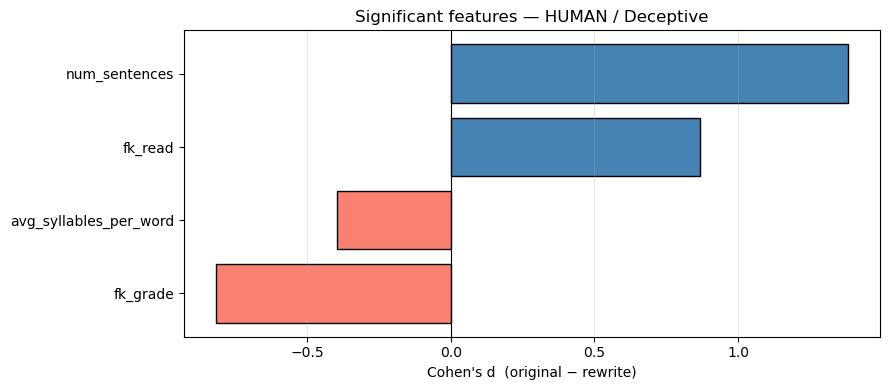


human / Truthful: no significant features after Holm correction.


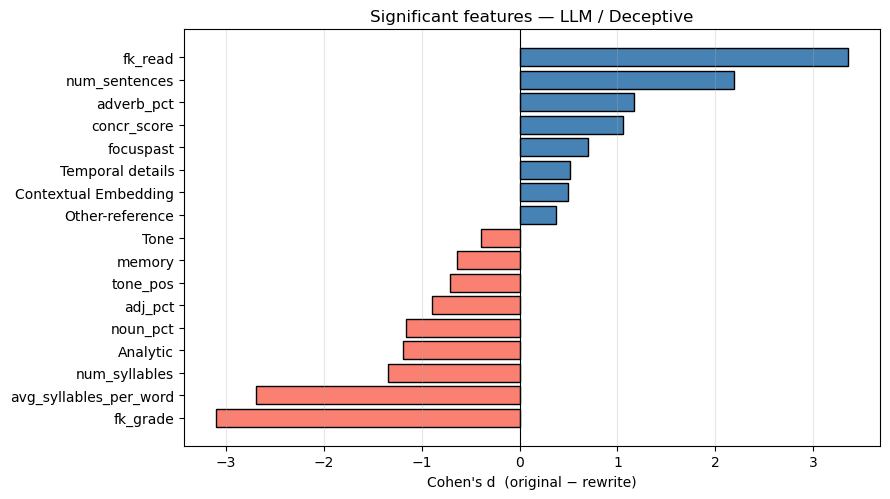

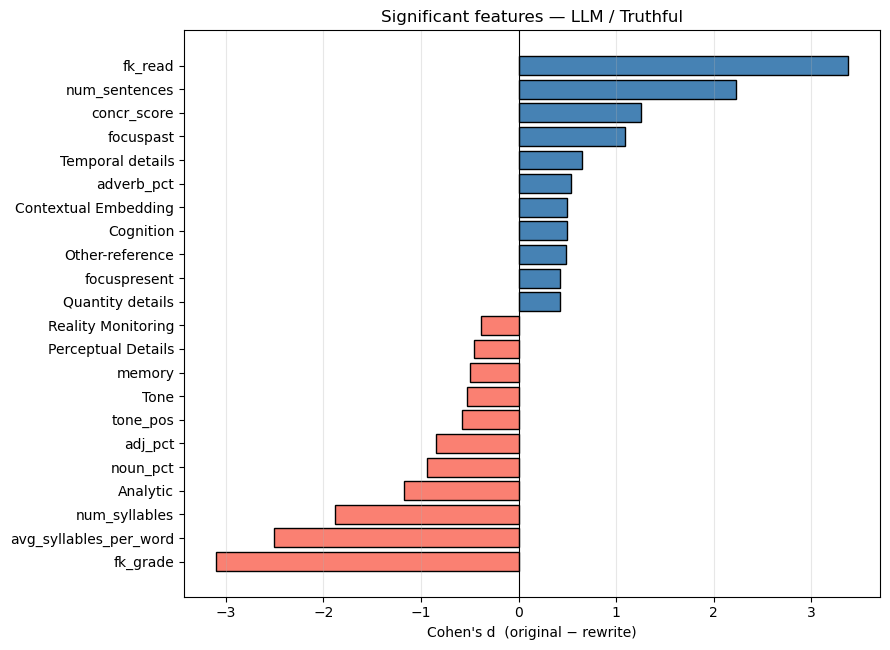

In [39]:
# ── Cohen's d bar charts for each modality × veracity with significant features ──
for modality in modalities:
    for veracity in veracities:
        if veracity not in veracity_results[modality]:
            continue
        res_df = veracity_results[modality][veracity]
        sig_df = res_df[res_df['null_h_rejected']].sort_values('effect_size_cohens_d', ascending=True)

        if sig_df.empty:
            print(f"\n{modality} / {veracity}: no significant features after Holm correction.")
            continue

        fig, ax = plt.subplots(figsize=(9, max(4, 0.3 * len(sig_df))))
        colors = ['steelblue' if s > 0 else 'salmon' for s in sig_df['stat']]
        ax.barh(sig_df['feature'], sig_df['effect_size_cohens_d'], color=colors, edgecolor='black')
        ax.axvline(0, color='black', linewidth=0.8)
        ax.set_xlabel("Cohen's d  (original − rewrite)")
        ax.set_title(f"Significant features — {modality.upper()} / {veracity}")
        ax.grid(axis='x', alpha=0.3)
        plt.tight_layout()
        plt.show()


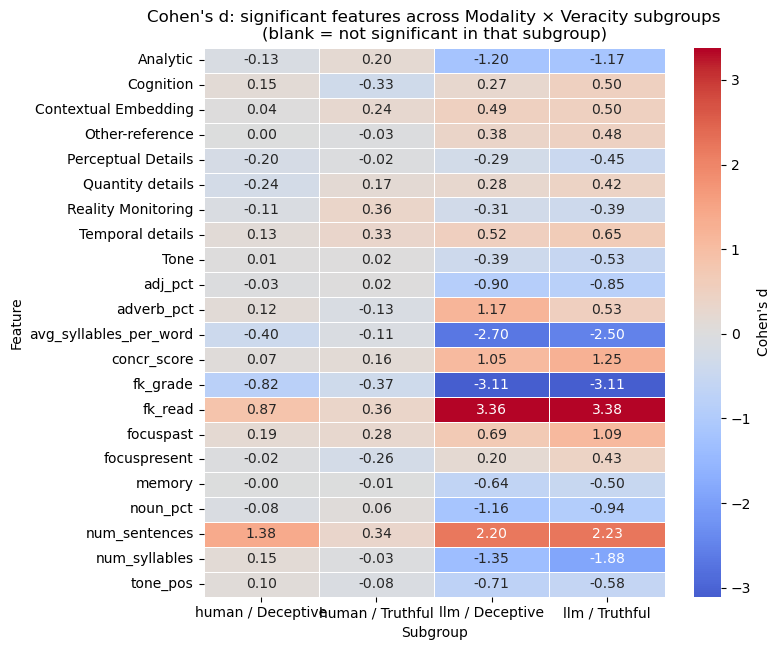


Significance summary (1 = Holm-corrected p < 0.05, 0 = not significant):


,human / Deceptive,human / Truthful,llm / Deceptive,llm / Truthful
Analytic,0.0,0.0,1.0,1.0
Cognition,0.0,0.0,0.0,1.0
Contextual Embedding,0.0,0.0,1.0,1.0
Other-reference,0.0,0.0,1.0,1.0
Perceptual Details,0.0,0.0,0.0,1.0
Quantity details,0.0,0.0,0.0,1.0
Reality Monitoring,0.0,0.0,0.0,1.0
Temporal details,0.0,0.0,1.0,1.0
Tone,0.0,0.0,1.0,1.0
adj_pct,0.0,0.0,1.0,1.0


In [40]:
# ── Summary heatmap: Cohen's d across modality × veracity subgroups ───────────
# Collect all features that are significant in at least one subgroup
all_sig = set()
for modality in modalities:
    for veracity in veracities:
        if veracity in veracity_results[modality]:
            df_sig = veracity_results[modality][veracity]
            all_sig.update(df_sig[df_sig['null_h_rejected']]['feature'].tolist())

if all_sig:
    col_order = [f"{m} / {v}" for m in modalities for v in veracities
                 if v in veracity_results[m]]
    heat_df = pd.DataFrame(index=sorted(all_sig), columns=col_order, dtype=float)

    for modality in modalities:
        for veracity in veracities:
            col_label = f"{modality} / {veracity}"
            if veracity not in veracity_results[modality]:
                continue
            sub = veracity_results[modality][veracity].set_index('feature')
            for feat in all_sig:
                if feat in sub.index:
                    heat_df.loc[feat, col_label] = sub.loc[feat, 'effect_size_cohens_d']

    fig, ax = plt.subplots(figsize=(max(8, len(col_order) * 2), max(5, 0.3 * len(all_sig))))
    sns.heatmap(
        heat_df.astype(float),
        ax=ax,
        cmap='coolwarm',
        center=0,
        annot=True,
        fmt='.2f',
        linewidths=0.5,
        cbar_kws={'label': "Cohen's d"},
    )
    ax.set_title("Cohen's d: significant features across Modality × Veracity subgroups\n"
                 "(blank = not significant in that subgroup)")
    ax.set_xlabel("Subgroup")
    ax.set_ylabel("Feature")
    plt.tight_layout()
    plt.show()

    print("\nSignificance summary (1 = Holm-corrected p < 0.05, 0 = not significant):")
    sig_summary = pd.DataFrame(index=sorted(all_sig), columns=col_order, dtype=int)
    for modality in modalities:
        for veracity in veracities:
            col_label = f"{modality} / {veracity}"
            if veracity not in veracity_results[modality]:
                continue
            sub = veracity_results[modality][veracity].set_index('feature')
            for feat in all_sig:
                if feat in sub.index:
                    sig_summary.loc[feat, col_label] = int(sub.loc[feat, 'null_h_rejected'])
                else:
                    sig_summary.loc[feat, col_label] = 0
    display(sig_summary)
else:
    print("No significant features found across any subgroup.")


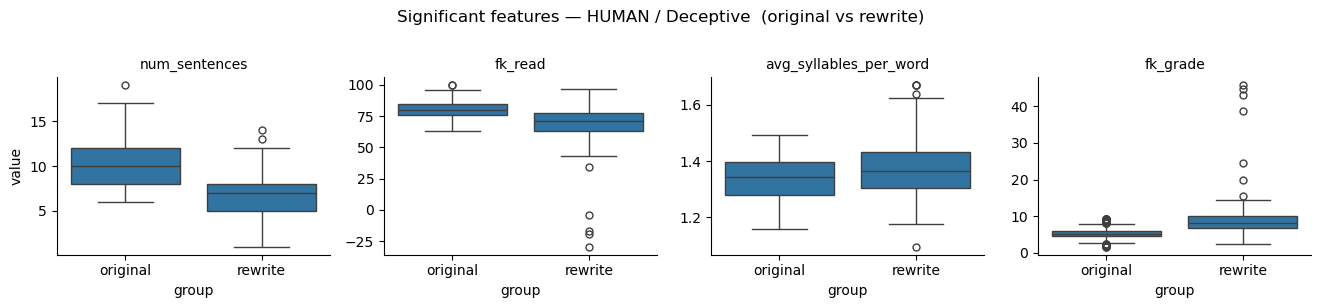


human / Truthful: no significant features to plot.


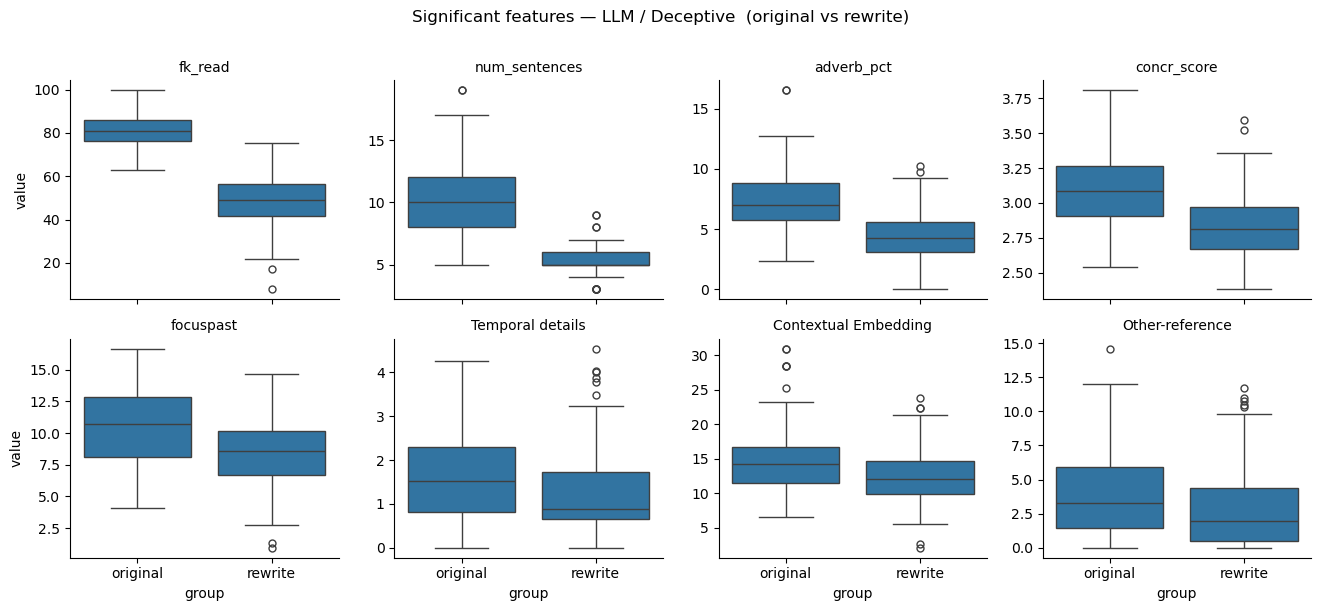

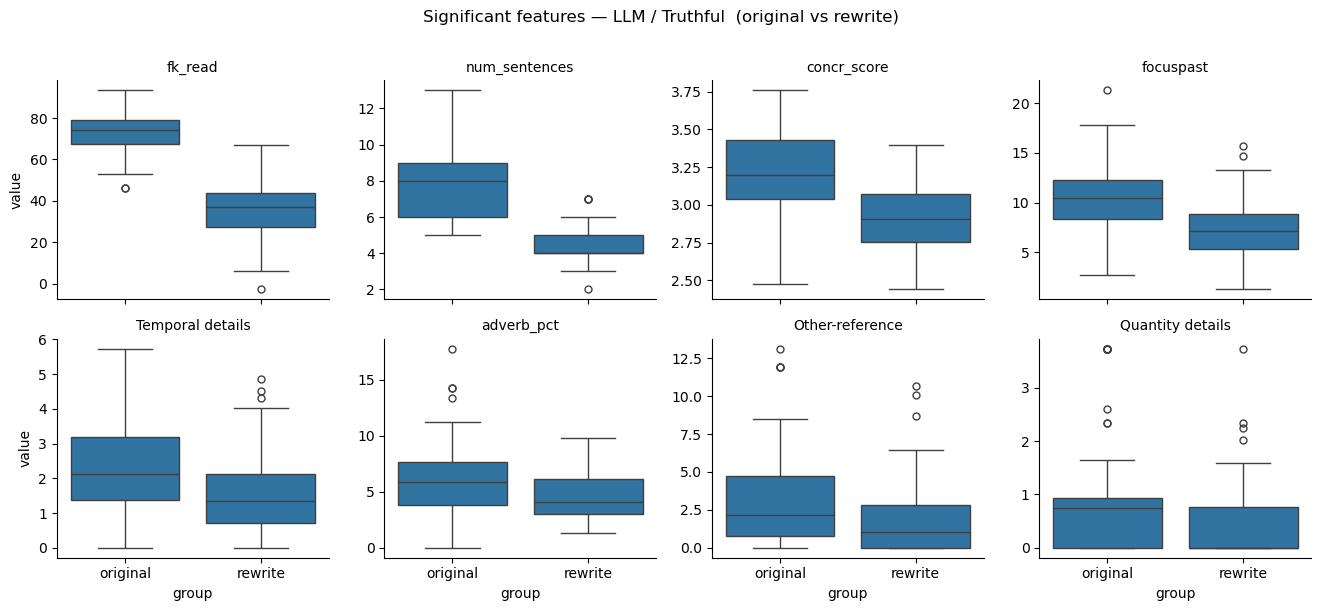

In [41]:
# ── Boxplots: significant features per modality × veracity subgroup ───────────
for modality in modalities:
    for veracity in veracities:
        if veracity not in veracity_results[modality]:
            continue
        res_df = veracity_results[modality][veracity]
        sig_features = res_df[res_df['null_h_rejected']]['feature'].tolist()

        if not sig_features:
            print(f"\n{modality} / {veracity}: no significant features to plot.")
            continue

        mask = (
            (scoring_with_keys['attack_modality'] == modality) &
            (scoring_with_keys['original_veracity'] == veracity)
        )
        subset_plot = scoring_with_keys[mask]

        plot_cols = ['text_type'] + sig_features[:8]   # cap at 8 for readability
        melted_sub = subset_plot[plot_cols].melt(
            id_vars='text_type', var_name='feature', value_name='value'
        )

        g = sns.catplot(
            data=melted_sub,
            x='text_type', y='value',
            col='feature', col_wrap=4,
            kind='box', sharey=False,
            height=3, aspect=1.1,
        )
        g.set_titles('{col_name}')
        g.set_axis_labels('group', 'value')
        g.fig.suptitle(
            f"Significant features — {modality.upper()} / {veracity}  "
            f"(original vs rewrite)",
            y=1.01
        )
        plt.tight_layout()
        plt.show()
